**PROJECT SETUP**

In [2]:
# ============================================================
# 01. PROJECT SETUP
# ============================================================

import os
import zipfile
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Paths
BASE_DIR = Path("/content")
ZIP_PATH = BASE_DIR / "Windows-APT 2025 A Dataset for APT-Inspired Attack.zip"
EXTRACT_DIR = BASE_DIR / "APT_Dataset"
OUTPUT_DIR = BASE_DIR / "APT_Project_Results"

OUTPUT_DIR.mkdir(exist_ok=True)

# Upload directly from local computer
from google.colab import files

if not ZIP_PATH.exists():
    uploaded = files.upload()

    uploaded_name = next(iter(uploaded))
    ZIP_PATH = BASE_DIR / uploaded_name

# Extract dataset
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

# Dataset paths
DATASET_DIR = (
    EXTRACT_DIR /
    "Windows-APT 2025 A Dataset for APT-Inspired Attack"
)

MAPPING_PATH = (
    DATASET_DIR /
    "scenario_mapping_supplement" /
    "log_to_scenario_mapping.csv"
)

COMBINED_PATH = DATASET_DIR / "combined.csv"

# Verify
assert DATASET_DIR.exists(), "Dataset directory not found"
assert MAPPING_PATH.exists(), "Mapping file not found"
assert COMBINED_PATH.exists(), "Combined CSV not found"

print("PROJECT SETUP COMPLETED")
print("=" * 50)
print("Dataset:", DATASET_DIR)
print("Mapping:", MAPPING_PATH)
print("Output:", OUTPUT_DIR)
print("Random seed:", SEED)

Saving Windows-APT 2025 A Dataset for APT-Inspired Attack.zip to Windows-APT 2025 A Dataset for APT-Inspired Attack.zip
PROJECT SETUP COMPLETED
Dataset: /content/APT_Dataset/Windows-APT 2025 A Dataset for APT-Inspired Attack
Mapping: /content/APT_Dataset/Windows-APT 2025 A Dataset for APT-Inspired Attack/scenario_mapping_supplement/log_to_scenario_mapping.csv
Output: /content/APT_Project_Results
Random seed: 42


**Load Mapping & Inspect Log Structure**

In [3]:
# ============================================================
# 02. DATASET STRUCTURE AND MAPPING INSPECTION
# ============================================================

# Load scenario mapping
mapping = pd.read_csv(MAPPING_PATH, low_memory=False)

# Identify original log files only
log_files = sorted([
    f for f in os.listdir(DATASET_DIR)
    if f.endswith(".csv")
    and f not in [
        "combined.csv",
        "scenario_manifest.csv",
        "validation_summary.csv"
    ]
])

# Inspect column names from the original logs
sample_log = pd.read_csv(
    DATASET_DIR / log_files[0],
    nrows=0
)

log_columns = sample_log.columns.tolist()

print("DATASET SUMMARY")
print("=" * 55)
print("Number of log files:", len(log_files))
print("Mapping records:", len(mapping))
print("Available log columns:", len(log_columns))

print("\nMAPPING LABEL DISTRIBUTION")
print("=" * 55)
print(mapping["Derived_Label"].value_counts(dropna=False))

print("\nRELEVANT LOG FEATURES")
print("=" * 55)

keywords = [
    "timestamp", "eventid", "agent",
    "process", "image", "command",
    "parent", "user", "ip", "port",
    "protocol", "destination", "source",
    "full_log", "rule"
]

candidate_columns = [
    col for col in log_columns
    if any(word in col.lower() for word in keywords)
]

for col in candidate_columns:
    print(col)

print("\nMAPPING READY:", not mapping.empty)
print("LOG STRUCTURE INSPECTED.")

DATASET SUMMARY
Number of log files: 16
Mapping records: 102011
Available log columns: 289

MAPPING LABEL DISTRIBUTION
Derived_Label
technique-tagged       63491
untagged               38392
technique-unmatched       86
NaN                       42
Name: count, dtype: int64

RELEVANT LOG FEATURES
_source.agent.name
_source.agent.id
_source.manager.name
_source.rule.firedtimes
_source.rule.mail
_source.rule.level
_source.rule.pci_dss
_source.rule.hipaa
_source.rule.tsc
_source.rule.description
_source.rule.groups
_source.rule.id
_source.rule.nist_800_53
_source.rule.gpg13
_source.rule.gdpr
_source.decoder.name
_source.full_log
_source.input.type
_source.@timestamp
_source.location
_source.id
_source.timestamp
_source.agent.ip
_source.data.win.eventdata.subjectLogonId
_source.data.win.eventdata.subjectDomainName
_source.data.win.eventdata.targetLinkedLogonId
_source.data.win.eventdata.impersonationLevel
_source.data.win.eventdata.authenticationPackageName
_source.data.win.eventdata.targe

**Load Original Logs and Construct Detection Labels**

In [4]:
# ============================================================
# 03. LOAD LOGS AND CONSTRUCT DETECTION LABELS
# ============================================================

FEATURE_COLUMNS = [
    "_source.@timestamp",
    "_source.agent.name",
    "_source.agent.id",
    "_source.data.win.system.eventID",
    "_source.data.win.system.providerName",
    "_source.data.win.system.channel",
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.originalFileName",
    "_source.data.win.eventdata.commandLine",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.parentCommandLine",
    "_source.data.win.eventdata.processName",
    "_source.data.win.eventdata.processId",
    "_source.data.win.eventdata.parentProcessId",
    "_source.data.win.eventdata.user",
    "_source.data.win.eventdata.integrityLevel",
    "_source.data.win.eventdata.logonType",
    "_source.data.win.eventdata.targetUserName",
    "_source.data.win.eventdata.subjectUserName",
    "_source.data.win.eventdata.destinationIp",
    "_source.data.win.eventdata.destinationPort",
    "_source.data.win.eventdata.sourceIp",
    "_source.data.win.eventdata.sourcePort",
    "_source.data.win.eventdata.protocol",
    "_source.data.win.eventdata.initiated",
    "_source.data.win.eventdata.targetFilename",
    "_source.data.win.eventdata.targetObject",
    "_source.data.win.eventdata.queryName",
    "_source.data.win.eventdata.eventType",
    "_source.syscheck.path",
    "_source.syscheck.event",
    "_source.data.process.name",
    "_source.data.process.cmd",
    "_source.data.command",
    "_source.decoder.name"
]

# Load selected columns from all original log files
log_frames = []

for filename in log_files:

    file_path = DATASET_DIR / filename

    temp = pd.read_csv(
        file_path,
        usecols=lambda col: col in FEATURE_COLUMNS,
        low_memory=False
    )

    # Preserve the original row position for mapping
    temp["Row_Index"] = np.arange(len(temp))
    temp["Source_CSV"] = filename

    log_frames.append(temp)

logs = pd.concat(log_frames, ignore_index=True)

# Prepare mapping keys
mapping["Row_Index"] = pd.to_numeric(
    mapping["Row_Index"], errors="raise"
).astype("int64")

# Attach labels and investigation metadata
mapping_subset = mapping[
    [
        "Source_CSV",
        "Row_Index",
        "Derived_Label",
        "Attribution_Strength",
        "Scenario_ID",
        "MITRE_Technique"
    ]
].copy()

df = logs.merge(
    mapping_subset,
    on=["Source_CSV", "Row_Index"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify mapping coverage
print("MAPPING VALIDATION")
print("=" * 55)
print(df["_merge"].value_counts())

assert (df["_merge"] == "both").all(), "Some log records were not mapped!"

df.drop(columns="_merge", inplace=True)

# Construct weak binary detection target
label_map = {
    "technique-tagged": 1,
    "technique-unmatched": 1,
    "untagged": 0
}

df["Target"] = df["Derived_Label"].map(label_map)

# Exclude records with unresolved/missing derived labels
df = df.dropna(subset=["Target"]).copy()
df["Target"] = df["Target"].astype("int8")

print("\nFINAL DETECTION DATASET")
print("=" * 55)
print("Records:", len(df))
print("Features loaded:", len(FEATURE_COLUMNS))
print("Positive records:", (df["Target"] == 1).sum())
print("Negative records:", (df["Target"] == 0).sum())
print("Excluded unresolved records:", 102011 - len(df))

print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nDataset shape:", df.shape)

MAPPING VALIDATION
_merge
both          102011
left_only          0
right_only         0
Name: count, dtype: int64

FINAL DETECTION DATASET
Records: 101969
Features loaded: 35
Positive records: 63577
Negative records: 38392
Excluded unresolved records: 42

Target distribution:
Target
1    63577
0    38392
Name: count, dtype: int64

Dataset shape: (101969, 42)


**Prepare Behavioral Features**

In [5]:
# ============================================================
# 04. FEATURE ENGINEERING
# ============================================================

# Helper: safely combine alternative columns
def combine_columns(data, columns):
    available = [c for c in columns if c in data.columns]
    if not available:
        return pd.Series("", index=data.index)

    result = data[available[0]].fillna("").astype(str)
    for col in available[1:]:
        result = result.replace("", np.nan).fillna(
            data[col].fillna("").astype(str)
        )
    return result.replace("nan", "")


# Build behavioral feature table
features = pd.DataFrame(index=df.index)

features["Event_ID"] = df[
    "_source.data.win.system.eventID"
].fillna("Unknown").astype(str)

features["Provider"] = df[
    "_source.data.win.system.providerName"
].fillna("Unknown").astype(str)

features["Channel"] = df[
    "_source.data.win.system.channel"
].fillna("Unknown").astype(str)

features["Process"] = combine_columns(
    df,
    [
        "_source.data.win.eventdata.image",
        "_source.data.win.eventdata.originalFileName",
        "_source.data.win.eventdata.processName",
        "_source.data.process.name"
    ]
)

features["Parent_Process"] = combine_columns(
    df,
    [
        "_source.data.win.eventdata.parentImage"
    ]
)

features["User"] = combine_columns(
    df,
    [
        "_source.data.win.eventdata.user",
        "_source.data.win.eventdata.subjectUserName",
        "_source.data.win.eventdata.targetUserName"
    ]
)

features["Integrity"] = df[
    "_source.data.win.eventdata.integrityLevel"
].fillna("Unknown").astype(str)

features["Logon_Type"] = df[
    "_source.data.win.eventdata.logonType"
].fillna("Unknown").astype(str)

features["Protocol"] = df[
    "_source.data.win.eventdata.protocol"
].fillna("Unknown").astype(str)

features["Decoder"] = df[
    "_source.decoder.name"
].fillna("Unknown").astype(str)

features["Command"] = combine_columns(
    df,
    [
        "_source.data.win.eventdata.commandLine",
        "_source.data.win.eventdata.parentCommandLine",
        "_source.data.process.cmd",
        "_source.data.command"
    ]
)

features["Destination_IP"] = df[
    "_source.data.win.eventdata.destinationIp"
].fillna("Unknown").astype(str)

features["Source_IP"] = df[
    "_source.data.win.eventdata.sourceIp"
].fillna("Unknown").astype(str)

features["Destination_Port"] = pd.to_numeric(
    df["_source.data.win.eventdata.destinationPort"],
    errors="coerce"
).fillna(-1)

features["Source_Port"] = pd.to_numeric(
    df["_source.data.win.eventdata.sourcePort"],
    errors="coerce"
).fillna(-1)

features["Target_File"] = combine_columns(
    df,
    [
        "_source.data.win.eventdata.targetFilename",
        "_source.syscheck.path"
    ]
)

features["Registry_Object"] = df[
    "_source.data.win.eventdata.targetObject"
].fillna("").astype(str)

features["DNS_Query"] = df[
    "_source.data.win.eventdata.queryName"
].fillna("").astype(str)

features["Event_Type"] = df[
    "_source.data.win.eventdata.eventType"
].fillna("Unknown").astype(str)

# Extract timestamp-based behavioral features
timestamps = pd.to_datetime(
    df["_source.@timestamp"],
    errors="coerce",
    utc=True
)

features["Hour"] = timestamps.dt.hour.fillna(-1)
features["Day_of_Week"] = timestamps.dt.dayofweek.fillna(-1)

# Numeric behavior indicators
features["Command_Length"] = features["Command"].str.len()
features["Has_Command"] = (features["Command"].str.len() > 0).astype(int)
features["Has_Network_Activity"] = (
    (features["Destination_IP"] != "Unknown") |
    (features["Source_IP"] != "Unknown")
).astype(int)
features["Has_File_Activity"] = (
    features["Target_File"].str.len() > 0
).astype(int)
features["Has_Registry_Activity"] = (
    features["Registry_Object"].str.len() > 0
).astype(int)
features["Has_DNS_Activity"] = (
    features["DNS_Query"].str.len() > 0
).astype(int)

# Suspicious command indicators (heuristic features)
suspicious_terms = [
    "powershell", "encodedcommand", "frombase64string",
    "downloadstring", "invoke-expression", " -enc ",
    "cmd.exe", "wscript", "cscript", " rundll32",
    "regsvr32", "schtasks", "wmic", "bitsadmin"
]

command_lower = features["Command"].str.lower()

features["Suspicious_Term_Count"] = sum(
    command_lower.str.contains(term, regex=False, na=False).astype(int)
    for term in suspicious_terms
)

# Target is kept separately from model features
y = df["Target"].copy()

print("FEATURE ENGINEERING COMPLETE")
print("=" * 55)
print("Feature matrix shape:", features.shape)
print("Target shape:", y.shape)
print("\nMissing values:")
print(features.isna().sum().sum())

print("\nFeature preview:")
display(features.head(5))

print("\nTarget distribution:")
print(y.value_counts())

FEATURE ENGINEERING COMPLETE
Feature matrix shape: (101969, 28)
Target shape: (101969,)

Missing values:
0

Feature preview:


,Event_ID,Provider,Channel,Process,Parent_Process,User,Integrity,Logon_Type,Protocol,Decoder,...,Event_Type,Hour,Day_of_Week,Command_Length,Has_Command,Has_Network_Activity,Has_File_Activity,Has_Registry_Activity,Has_DNS_Activity,Suspicious_Term_Count
0,,,,,,,,,,ossec,...,,-1.0,-1.0,1,1,1,1,1,1,0
1,4624,Microsoft-Windows-Security-Auditing,Security,,,,,5,,windows_eventchannel,...,,-1.0,-1.0,1,1,1,1,1,1,0
2,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,System,,,windows_eventchannel,...,,-1.0,-1.0,36,1,1,1,1,1,0
3,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,System,,,windows_eventchannel,...,,-1.0,-1.0,22,1,1,1,1,1,0
4,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,System,,,windows_eventchannel,...,,-1.0,-1.0,22,1,1,1,1,1,0



Target distribution:
Target
1    63577
0    38392
Name: count, dtype: int64


**Validate Engineered Features**

In [6]:
# ============================================================
# 05. FEATURE QUALITY VALIDATION
# ============================================================

check_columns = [
    "Command", "Destination_IP", "Source_IP",
    "Target_File", "Registry_Object", "DNS_Query"
]

print("RAW VALUES CHECK")
print("=" * 60)

for col in check_columns:
    print(f"\n{col}:")
    print(features[col].head(10).map(repr).tolist())
    print("Empty strings:", (features[col] == "").sum())
    print("Literal nan:", features[col].str.lower().eq("nan").sum())
    print("Literal none:", features[col].str.lower().eq("none").sum())

print("\nINDICATOR DISTRIBUTIONS")
print("=" * 60)

indicator_columns = [
    "Has_Command",
    "Has_Network_Activity",
    "Has_File_Activity",
    "Has_Registry_Activity",
    "Has_DNS_Activity"
]

for col in indicator_columns:
    print(f"\n{col}:")
    print(features[col].value_counts(dropna=False))

print("\nTIMESTAMP CHECK")
print("=" * 60)
print("Original timestamp samples:")
print(df["_source.@timestamp"].head(10).map(repr).tolist())

print("\nParsed timestamp samples:")
print(timestamps.head(10).tolist())

print("\nValid timestamps:", timestamps.notna().sum())
print("Invalid timestamps:", timestamps.isna().sum())

RAW VALUES CHECK

Command:
["' '", "' '", "'C:\\\\\\\\Windows\\\\\\\\system32\\\\\\\\net1 accounts'", "'net user administrator'", "'net user administrator'", "'C:\\\\\\\\Windows\\\\\\\\system32\\\\\\\\net1 user administrator'", "'net.exe accounts'", "'C:\\\\\\\\Windows\\\\\\\\system32\\\\\\\\net1 accounts'", "'net.exe accounts'", "' '"]
Empty strings: 0
Literal nan: 0
Literal none: 0

Destination_IP:
["' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '"]
Empty strings: 0
Literal nan: 0
Literal none: 0

Source_IP:
["' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '"]
Empty strings: 0
Literal nan: 0
Literal none: 0

Target_File:
["' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '"]
Empty strings: 0
Literal nan: 0
Literal none: 0

Registry_Object:
["' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '"]
Empty strings: 7233
Literal nan: 0
Literal none: 0

DNS_Query:
["' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '", "' '

**Fix Missing Values and Timestamp Parsing**

In [7]:
# ============================================================
# 06. CLEAN FEATURES AND FIX TIMESTAMPS
# ============================================================

def clean_text(series):
    s = series.fillna("").astype(str).str.strip()
    return s.mask(s.str.lower().isin(["nan", "none", "null", "<na>"]), "")


def combine_clean_columns(data, columns):
    available = [c for c in columns if c in data.columns]

    if not available:
        return pd.Series("", index=data.index)

    temp = pd.DataFrame({
        c: clean_text(data[c]) for c in available
    })

    temp = temp.replace("", np.nan)
    return temp.bfill(axis=1).iloc[:, 0].fillna("")


# Rebuild fields using cleaned values and proper fallback
features["Process"] = combine_clean_columns(
    df, [
        "_source.data.win.eventdata.image",
        "_source.data.win.eventdata.originalFileName",
        "_source.data.win.eventdata.processName",
        "_source.data.process.name"
    ]
)

features["Parent_Process"] = clean_text(
    df["_source.data.win.eventdata.parentImage"]
)

features["User"] = combine_clean_columns(
    df, [
        "_source.data.win.eventdata.user",
        "_source.data.win.eventdata.subjectUserName",
        "_source.data.win.eventdata.targetUserName"
    ]
)

features["Command"] = combine_clean_columns(
    df, [
        "_source.data.win.eventdata.commandLine",
        "_source.data.win.eventdata.parentCommandLine",
        "_source.data.process.cmd",
        "_source.data.command"
    ]
)

features["Target_File"] = combine_clean_columns(
    df, [
        "_source.data.win.eventdata.targetFilename",
        "_source.syscheck.path"
    ]
)

# Clean remaining categorical fields
text_columns = [
    "Event_ID", "Provider", "Channel", "Integrity",
    "Logon_Type", "Protocol", "Decoder",
    "Destination_IP", "Source_IP",
    "Registry_Object", "DNS_Query", "Event_Type"
]

for col in text_columns:
    features[col] = clean_text(features[col])

# Standardize missing categorical values
for col in [
    "Event_ID", "Provider", "Channel", "Integrity",
    "Logon_Type", "Protocol", "Decoder",
    "Destination_IP", "Source_IP"
]:
    features[col] = features[col].replace("", "Unknown")

# Parse the actual timestamp format
timestamps = pd.to_datetime(
    df["_source.@timestamp"],
    format="%b %d, %Y @ %H:%M:%S.%f",
    errors="coerce",
    utc=True
)

features["Hour"] = timestamps.dt.hour.fillna(-1)
features["Day_of_Week"] = timestamps.dt.dayofweek.fillna(-1)

# Recalculate behavioral indicators
features["Command_Length"] = features["Command"].str.len()

features["Has_Command"] = (
    features["Command"].str.len() > 0
).astype(int)

features["Has_Network_Activity"] = (
    (features["Destination_IP"] != "Unknown") |
    (features["Source_IP"] != "Unknown")
).astype(int)

features["Has_File_Activity"] = (
    features["Target_File"].str.len() > 0
).astype(int)

features["Has_Registry_Activity"] = (
    features["Registry_Object"].str.len() > 0
).astype(int)

features["Has_DNS_Activity"] = (
    features["DNS_Query"].str.len() > 0
).astype(int)

# Recalculate suspicious command indicators
command_lower = features["Command"].str.lower()

features["Suspicious_Term_Count"] = sum(
    command_lower.str.contains(term, regex=False, na=False).astype(int)
    for term in suspicious_terms
)

print("CLEANING RESULTS")
print("=" * 55)

print("Valid timestamps:", timestamps.notna().sum())
print("Invalid timestamps:", timestamps.isna().sum())

print("\nIndicator distributions:")
for col in indicator_columns:
    print(f"\n{col}:")
    print(features[col].value_counts())

print("\nUpdated feature preview:")
display(features.head())

print("\nFeature matrix shape:", features.shape)

CLEANING RESULTS
Valid timestamps: 101969
Invalid timestamps: 0

Indicator distributions:

Has_Command:
Has_Command
0    81076
1    20893
Name: count, dtype: int64

Has_Network_Activity:
Has_Network_Activity
0    101502
1       467
Name: count, dtype: int64

Has_File_Activity:
Has_File_Activity
0    70825
1    31144
Name: count, dtype: int64

Has_Registry_Activity:
Has_Registry_Activity
0    101022
1       947
Name: count, dtype: int64

Has_DNS_Activity:
Has_DNS_Activity
0    98034
1     3935
Name: count, dtype: int64

Updated feature preview:


,Event_ID,Provider,Channel,Process,Parent_Process,User,Integrity,Logon_Type,Protocol,Decoder,...,Event_Type,Hour,Day_of_Week,Command_Length,Has_Command,Has_Network_Activity,Has_File_Activity,Has_Registry_Activity,Has_DNS_Activity,Suspicious_Term_Count
0,Unknown,Unknown,Unknown,,,,Unknown,Unknown,Unknown,ossec,...,,20,5,0,0,0,0,0,0,0
1,4624,Microsoft-Windows-Security-Auditing,Security,C:\\Windows\\System32\\services.exe,,DESKTOP-FMI6MML$,Unknown,5,Unknown,windows_eventchannel,...,,6,6,0,0,0,0,0,0,0
2,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,System,Unknown,Unknown,windows_eventchannel,...,,6,6,36,1,0,0,0,0,0
3,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,System,Unknown,Unknown,windows_eventchannel,...,,6,6,22,1,0,0,0,0,0
4,1,Microsoft-Windows-Sysmon,Microsoft-Windows-Sysmon/Operational,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,System,Unknown,Unknown,windows_eventchannel,...,,6,6,22,1,0,0,0,0,0



Feature matrix shape: (101969, 28)


**Check Log Source Distribution**

In [8]:
# ============================================================
# 07. CHECK DATA DISTRIBUTION BY LOG SOURCE
# ============================================================

source_stats = df.groupby("Source_CSV").agg(
    Records=("Target", "size"),
    Positive=("Target", "sum"),
    Positive_Ratio=("Target", "mean")
).sort_values("Records", ascending=False)

source_stats["Negative"] = (
    source_stats["Records"] - source_stats["Positive"]
)

source_stats["Positive_Ratio"] = (
    source_stats["Positive_Ratio"] * 100
).round(2)

print("LOG SOURCE DISTRIBUTION")
print("=" * 65)
display(source_stats)

print("\nNumber of log sources:", df["Source_CSV"].nunique())
print("Sources containing both classes:",
      ((source_stats["Positive"] > 0) &
       (source_stats["Negative"] > 0)).sum())

print("\nLog file names:")
for name in sorted(df["Source_CSV"].unique()):
    print("-", name)

LOG SOURCE DISTRIBUTION


,Records,Positive,Positive_Ratio,Negative
Source_CSV,,,,
13-14-December.csv,9738,5020,51.55,4718
11-12-December.csv,9653,5685,58.89,3968
07-10-December.csv,9181,6619,72.09,2562
10-December-P1.csv,9049,5255,58.07,3794
01-03-December.csv,8836,6903,78.12,1933
1-11-November.csv,8799,6872,78.10,1927
23-30-November.csv,8034,6392,79.56,1642
04-07-December.csv,7748,5512,71.14,2236
03-04-December.csv,7291,4868,66.77,2423



Number of log sources: 16
Sources containing both classes: 16

Log file names:
- 01-03-December.csv
- 03-04-December.csv
- 04-07-December.csv
- 07-10-December.csv
- 1-11-November.csv
- 10-December-P1.csv
- 10-December-P2.csv
- 11-12-December.csv
- 11-16-November.csv
- 12-13-December.csv
- 13-14-December.csv
- 14-17-December.csv
- 22-December.csv
- 23-30-November.csv
- 28-October-01-November.csv
- 30-November.csv


**Chronological Train/Test Split**

In [9]:
# ============================================================
# 08. CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

test_sources = [
    "12-13-December.csv",
    "13-14-December.csv",
    "14-17-December.csv",
    "22-December.csv"
]

train_mask = ~df["Source_CSV"].isin(test_sources)
test_mask = df["Source_CSV"].isin(test_sources)

X_train = features.loc[train_mask].copy()
X_test = features.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("CHRONOLOGICAL SPLIT")
print("=" * 55)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training period: Earlier log files")
print("Testing files:")
for source in test_sources:
    print(" -", source)

print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nPositive ratios:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Test :", round(y_test.mean() * 100, 2), "%")

assert len(X_train) + len(X_test) == len(features)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert y_train.nunique() == 2
assert y_test.nunique() == 2

print("\nSplit validation: PASSED")

CHRONOLOGICAL SPLIT
Training records: 79014
Testing records: 22955
Training period: Earlier log files
Testing files:
 - 12-13-December.csv
 - 13-14-December.csv
 - 14-17-December.csv
 - 22-December.csv

Training target distribution:
Target
1    51627
0    27387
Name: count, dtype: int64

Testing target distribution:
Target
1    11950
0    11005
Name: count, dtype: int64

Positive ratios:
Train: 65.34 %
Test : 52.06 %

Split validation: PASSED


**Prepare ML Input Features**

In [10]:
# ============================================================
# 09. PREPARE STRUCTURED ML FEATURES
# ============================================================

X_model = pd.DataFrame(index=features.index)

# Categorical behavioral features
categorical_columns = [
    "Event_ID",
    "Provider",
    "Channel",
    "Integrity",
    "Logon_Type",
    "Protocol",
    "Decoder",
    "Event_Type"
]

for col in categorical_columns:
    X_model[col] = clean_text(features[col]).replace("", "Unknown")

# Extract executable names instead of full file paths
X_model["Process_Name"] = (
    features["Process"]
    .str.replace("/", "\\", regex=False)
    .str.split("\\", regex=False)
    .str[-1]
    .str.lower()
    .replace("", "Unknown")
)

X_model["Parent_Process_Name"] = (
    features["Parent_Process"]
    .str.replace("/", "\\", regex=False)
    .str.split("\\", regex=False)
    .str[-1]
    .str.lower()
    .replace("", "Unknown")
)

categorical_columns += ["Process_Name", "Parent_Process_Name"]

# Numeric behavioral features
numeric_columns = [
    "Hour",
    "Day_of_Week",
    "Command_Length",
    "Destination_Port",
    "Source_Port",
    "Has_Command",
    "Has_Network_Activity",
    "Has_File_Activity",
    "Has_Registry_Activity",
    "Has_DNS_Activity",
    "Suspicious_Term_Count"
]

for col in numeric_columns:
    X_model[col] = pd.to_numeric(
        features[col], errors="coerce"
    ).fillna(-1)

# Recreate chronological split using the selected features
X_train_model = X_model.loc[train_mask].copy()
X_test_model = X_model.loc[test_mask].copy()

print("MODEL INPUT PREPARATION")
print("=" * 55)
print("Total input features:", X_model.shape[1])
print("Categorical features:", len(categorical_columns))
print("Numeric features:", len(numeric_columns))
print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)

print("\nMissing values:", X_model.isna().sum().sum())
print("\nCategorical cardinality:")
display(
    X_model[categorical_columns]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("Unique_Values")
)

assert X_model.isna().sum().sum() == 0
assert X_train_model.index.equals(y_train.index)
assert X_test_model.index.equals(y_test.index)

print("\nML INPUT VALIDATION: PASSED")

MODEL INPUT PREPARATION
Total input features: 21
Categorical features: 10
Numeric features: 11
Training shape: (79014, 21)
Testing shape: (22955, 21)

Missing values: 0

Categorical cardinality:


,Unique_Values
Process_Name,135
Event_ID,87
Parent_Process_Name,30
Provider,29
Decoder,22
Channel,5
Integrity,4
Logon_Type,4
Event_Type,4
Protocol,2



ML INPUT VALIDATION: PASSED


**Preprocessing and Model Training**

In [11]:
# ============================================================
# 10. PREPROCESSING AND MODEL TRAINING
# ============================================================

import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_columns
        )
    ]
)

print("Fitting preprocessing pipeline...")

X_train_processed = preprocessor.fit_transform(X_train_model)
X_test_processed = preprocessor.transform(X_test_model)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# Model 1: Logistic Regression
print("\nTraining Logistic Regression...")

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED,
    solver="liblinear"
)

start = time.time()
lr_model.fit(X_train_processed, y_train)
lr_training_time = time.time() - start

print("Logistic Regression training completed.")
print("Training time:", round(lr_training_time, 2), "seconds")

# Model 2: Random Forest
print("\nTraining Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=120,
    max_depth=18,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

start = time.time()
rf_model.fit(X_train_processed, y_train)
rf_training_time = time.time() - start

print("Random Forest training completed.")
print("Training time:", round(rf_training_time, 2), "seconds")

print("\nBOTH MODELS TRAINED SUCCESSFULLY.")

Fitting preprocessing pipeline...
Processed training shape: (79014, 321)
Processed testing shape: (22955, 321)

Training Logistic Regression...
Logistic Regression training completed.
Training time: 1.4 seconds

Training Random Forest...
Random Forest training completed.
Training time: 9.77 seconds

BOTH MODELS TRAINED SUCCESSFULLY.


**Install and Prepare XGBoost**

In [12]:
# ============================================================
# 11. INSTALL AND PREPARE ADDITIONAL MODELS
# ============================================================

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])

from xgboost import XGBClassifier

print("XGBoost is ready.")

print("\nExisting trained models:")
print("- Logistic Regression")
print("- Random Forest")

print("\nAdditional models to train:")
print("- XGBoost")
print("- HistGradientBoosting")
print("- MLP")
print("- Autoencoder")

XGBoost is ready.

Existing trained models:
- Logistic Regression
- Random Forest

Additional models to train:
- XGBoost
- HistGradientBoosting
- MLP
- Autoencoder


**Train XGBoost**

In [13]:
# ============================================================
# 12. TRAIN XGBOOST
# ============================================================

import time
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=7,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=SEED,
    n_jobs=-1
)

print("Training XGBoost...")

start = time.time()

xgb_model.fit(
    X_train_processed,
    y_train
)

xgb_training_time = time.time() - start

print("\nXGBoost training completed.")
print("Training time:", round(xgb_training_time, 2), "seconds")

print("\nModels currently trained:")
print("- Logistic Regression")
print("- Random Forest")
print("- XGBoost")

Training XGBoost...

XGBoost training completed.
Training time: 5.31 seconds

Models currently trained:
- Logistic Regression
- Random Forest
- XGBoost


**Train HistGradientBoosting**

In [14]:
# ============================================================
# 13. TRAIN HISTGRADIENTBOOSTING
# ============================================================

from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.sparse import issparse
import time

print("Preparing dense input...")

X_train_dense = (
    X_train_processed.toarray()
    if issparse(X_train_processed)
    else X_train_processed
)

print("Dense training shape:", X_train_dense.shape)

hgb_model = HistGradientBoostingClassifier(
    max_iter=150,
    max_leaf_nodes=31,
    learning_rate=0.08,
    l2_regularization=1.0,
    class_weight="balanced",
    random_state=SEED
)

print("\nTraining HistGradientBoosting...")

start = time.time()

hgb_model.fit(
    X_train_dense,
    y_train
)

hgb_training_time = time.time() - start

print("\nHistGradientBoosting training completed.")
print("Training time:", round(hgb_training_time, 2), "seconds")

print("\nModels currently trained:")
print("- Logistic Regression")
print("- Random Forest")
print("- XGBoost")
print("- HistGradientBoosting")

Preparing dense input...
Dense training shape: (79014, 321)

Training HistGradientBoosting...

HistGradientBoosting training completed.
Training time: 33.39 seconds

Models currently trained:
- Logistic Regression
- Random Forest
- XGBoost
- HistGradientBoosting


**Train MLP Neural Network**

In [15]:

from sklearn.neural_network import MLPClassifier
import time

print("Training MLP Neural Network...")

start = time.time()

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=SEED,
    verbose=False
)

mlp_model.fit(X_train_processed, y_train)

mlp_training_time = time.time() - start

print("MLP training completed.")
print(f"Training time: {mlp_training_time:.2f} seconds")
print(f"Iterations completed: {mlp_model.n_iter_}")


Training MLP Neural Network...
MLP training completed.
Training time: 29.18 seconds
Iterations completed: 11


**Prepare Autoencoder Data**

In [16]:

from sklearn.model_selection import train_test_split
from scipy.sparse import issparse

print("Preparing Autoencoder data...")

# Convert training data to float32 dense format
X_ae_all = (
    X_train_processed.toarray().astype(np.float32)
    if issparse(X_train_processed)
    else np.asarray(X_train_processed, dtype=np.float32)
)

# Select normal records only
normal_indices = np.where(y_train.to_numpy() == 0)[0]

# Split normal records into training and calibration sets
normal_fit_idx, normal_cal_idx = train_test_split(
    normal_indices,
    test_size=0.20,
    random_state=SEED
)

X_ae_fit = X_ae_all[normal_fit_idx]
X_ae_cal = X_ae_all[normal_cal_idx]

print("Autoencoder training shape:", X_ae_fit.shape)
print("Normal calibration shape:", X_ae_cal.shape)
print("Autoencoder input features:", X_ae_fit.shape[1])


Preparing Autoencoder data...
Autoencoder training shape: (21909, 321)
Normal calibration shape: (5478, 321)
Autoencoder input features: 321


**Build and Train Autoencoder**

In [17]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

tf.random.set_seed(SEED)

input_dim = X_ae_fit.shape[1]

inputs = keras.Input(shape=(input_dim,))

# Encoder
x = layers.Dense(128, activation="relu")(inputs)
x = layers.Dense(64, activation="relu")(x)
encoded = layers.Dense(32, activation="relu")(x)

# Decoder
x = layers.Dense(64, activation="relu")(encoded)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(input_dim, activation="linear")(x)

autoencoder = keras.Model(inputs, outputs)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

print("Training Autoencoder...")

start = time.time()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

autoencoder_history = autoencoder.fit(
    X_ae_fit,
    X_ae_fit,
    validation_split=0.1,
    epochs=20,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

ae_training_time = time.time() - start

print("\nAutoencoder training completed.")
print(f"Training time: {ae_training_time:.2f} seconds")
print("Epochs completed:", len(autoencoder_history.history["loss"]))


Training Autoencoder...
Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0308 - val_loss: 0.0169
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0116 - val_loss: 0.0072
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0050 - val_loss: 0.0032
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0027 - val_loss: 0.0022
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0015 - val_loss: 0.0012
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0011 - val_loss: 9.5837e-04
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 9.7472e-04 - val_loss: 8.5530e-04
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 8.7667e-04 - val_loss: 7.7174e-04
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 8.0195e-04 - val_loss: 7.1360e-04
Epoch 12/20

**Calculate Autoencoder Threshold**

In [18]:

import numpy as np

print("Calculating reconstruction errors...")

# Reconstruction error for normal calibration records
cal_reconstructed = autoencoder.predict(
    X_ae_cal, batch_size=512, verbose=0
)

cal_errors = np.mean(
    np.square(X_ae_cal - cal_reconstructed),
    axis=1
)

# Set threshold using the 95th percentile
ae_threshold = np.percentile(cal_errors, 95)

print("Autoencoder threshold calculated.")
print(f"Threshold: {ae_threshold:.8f}")
print(f"Calibration mean error: {cal_errors.mean():.8f}")
print(f"Calibration 95th percentile: {ae_threshold:.8f}")
print(f"Calibration maximum error: {cal_errors.max():.8f}")


Calculating reconstruction errors...
Autoencoder threshold calculated.
Threshold: 0.00337308
Calibration mean error: 0.00045887
Calibration 95th percentile: 0.00337308
Calibration maximum error: 0.02952905


**Final Evaluation of All 6 Models**

In [19]:

import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
from scipy.sparse import issparse

print("Preparing test data...")

# Dense test data for HistGradientBoosting and Autoencoder
X_test_dense = (
    X_test_processed.toarray()
    if issparse(X_test_processed)
    else np.asarray(X_test_processed)
)

X_test_ae = X_test_dense.astype(np.float32)

y_true = y_test.to_numpy()

# Store model predictions and training times
model_predictions = {}
training_times = {
    "Logistic Regression": lr_training_time,
    "Random Forest": rf_training_time,
    "XGBoost": xgb_training_time,
    "HistGradientBoosting": hgb_training_time,
    "MLP Neural Network": mlp_training_time,
    "Autoencoder": ae_training_time
}

# Supervised models
supervised_models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "HistGradientBoosting": hgb_model,
    "MLP Neural Network": mlp_model
}

results = []

print("\nEvaluating supervised models...")

for name, model in supervised_models.items():

    start = time.time()

    if name == "HistGradientBoosting":
        probabilities = model.predict_proba(X_test_dense)[:, 1]
    else:
        probabilities = model.predict_proba(X_test_processed)[:, 1]

    prediction_time = time.time() - start
    predictions = (probabilities >= 0.5).astype(int)

    model_predictions[name] = {
        "predictions": predictions,
        "scores": probabilities
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Training_Time_sec": training_times[name],
        "Prediction_Time_sec": prediction_time
    })

    print(f"{name}: completed")

# Autoencoder evaluation
print("\nEvaluating Autoencoder...")

start = time.time()

ae_reconstructed = autoencoder.predict(
    X_test_ae, batch_size=512, verbose=0
)

ae_errors = np.mean(
    np.square(X_test_ae - ae_reconstructed),
    axis=1
)

ae_prediction_time = time.time() - start
ae_predictions = (ae_errors > ae_threshold).astype(int)

model_predictions["Autoencoder"] = {
    "predictions": ae_predictions,
    "scores": ae_errors
}

results.append({
    "Model": "Autoencoder",
    "Accuracy": accuracy_score(y_true, ae_predictions),
    "Precision": precision_score(y_true, ae_predictions, zero_division=0),
    "Recall": recall_score(y_true, ae_predictions, zero_division=0),
    "F1-Score": f1_score(y_true, ae_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, ae_errors),
    "PR-AUC": average_precision_score(y_true, ae_errors),
    "Training_Time_sec": training_times["Autoencoder"],
    "Prediction_Time_sec": ae_prediction_time
})

# Final comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 85)
print("FINAL MODEL EVALUATION RESULTS")
print("=" * 85)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Training_Time_sec": "{:.2f}",
        "Prediction_Time_sec": "{:.4f}"
    })
)

# Save evaluation results
results_df.to_csv(
    OUTPUT_DIR / "model_evaluation_results.csv",
    index=False
)

print("\nResults saved successfully.")


Preparing test data...

Evaluating supervised models...
Logistic Regression: completed
Random Forest: completed
XGBoost: completed
HistGradientBoosting: completed
MLP Neural Network: completed

Evaluating Autoencoder...

FINAL MODEL EVALUATION RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Training_Time_sec,Prediction_Time_sec
0,MLP Neural Network,0.9985,0.9992,0.9980,0.9986,0.9999,0.9999,29.18,0.1508
1,Logistic Regression,0.9984,0.9991,0.9979,0.9985,0.9997,0.9997,1.40,0.0033
2,XGBoost,0.9982,0.9992,0.9973,0.9983,0.9997,0.9997,5.31,0.2791
3,HistGradientBoosting,0.9980,0.9988,0.9972,0.9980,0.9998,0.9998,33.39,3.0212
4,Random Forest,0.9964,0.9992,0.9939,0.9965,0.9997,0.9997,9.77,0.3065
5,Autoencoder,0.9566,0.9438,0.9747,0.9590,0.9949,0.9948,13.88,0.7663



Results saved successfully.


**Confusion Matrices & ROC/PR Curves**

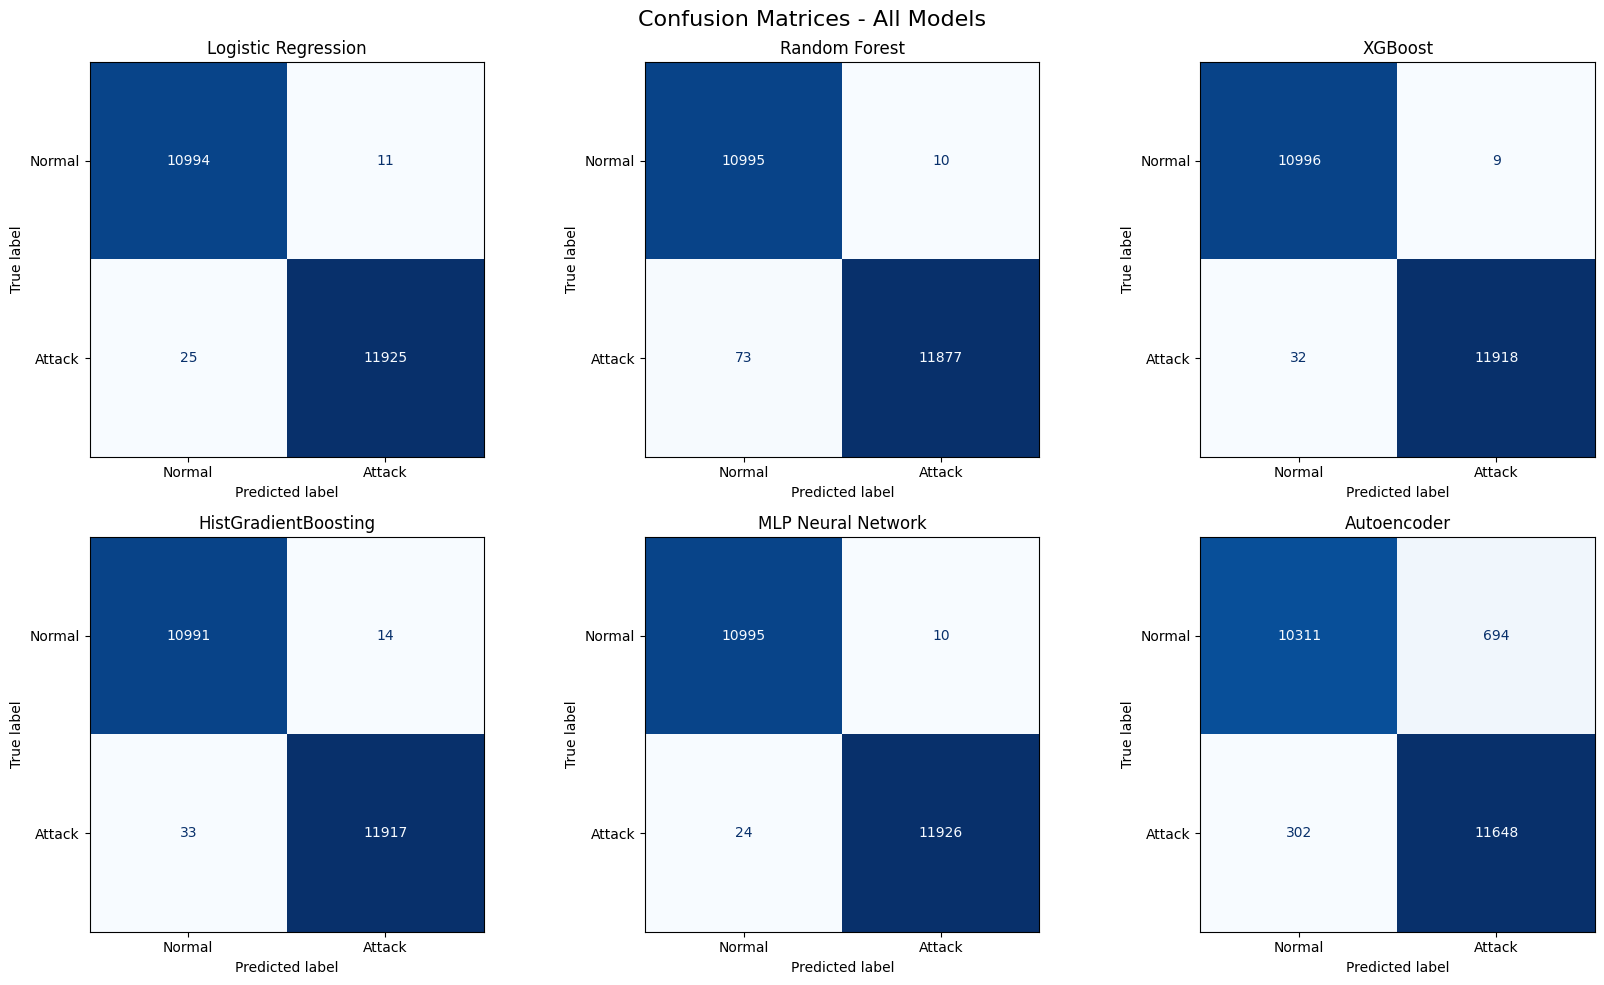

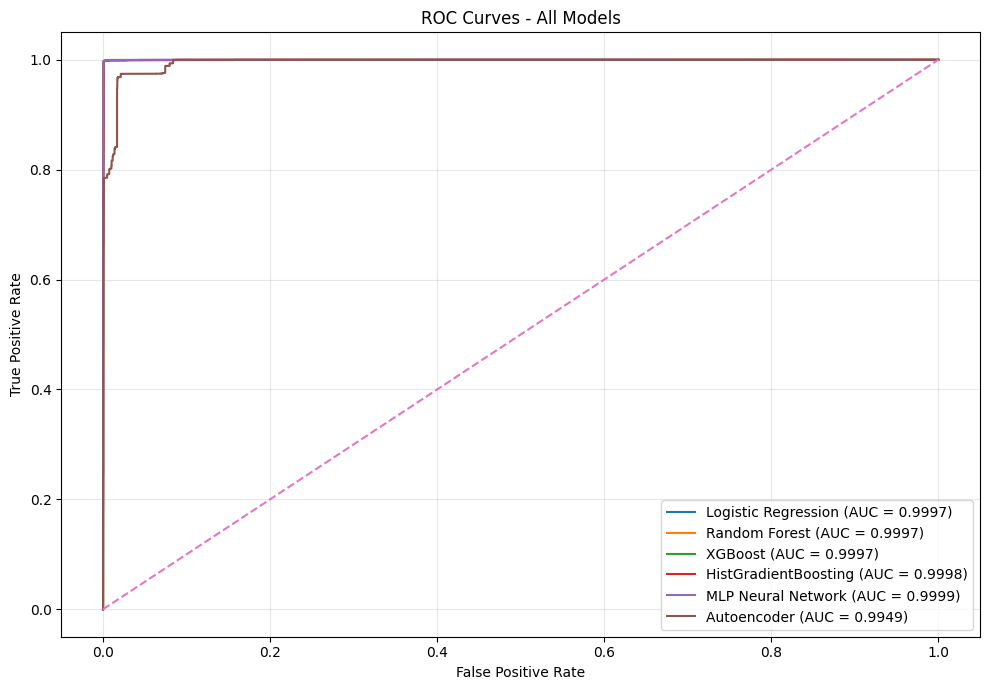

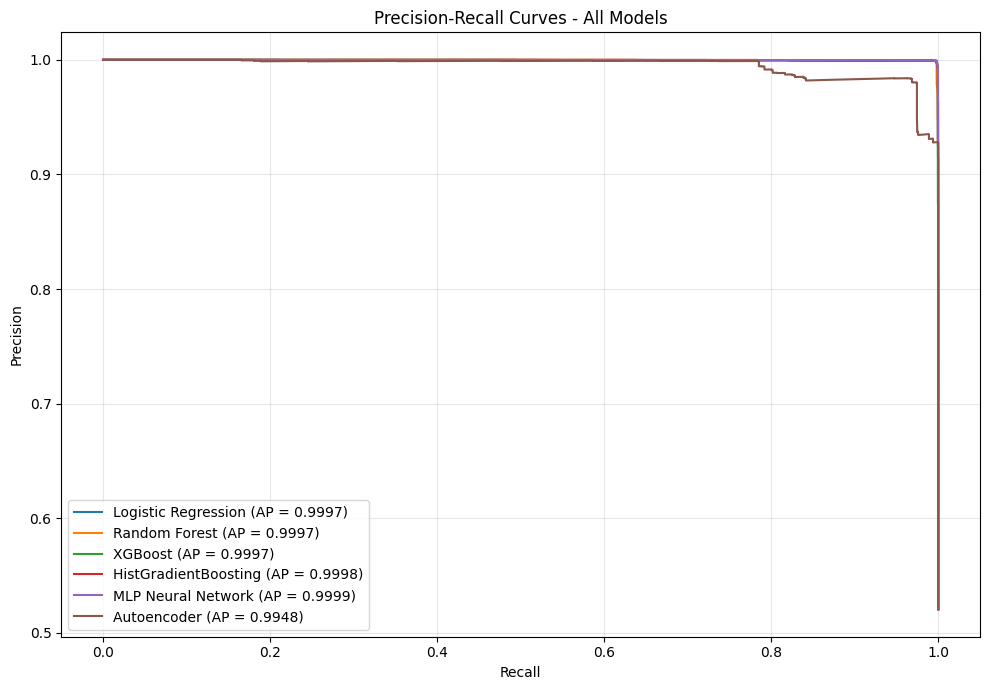

All evaluation plots saved successfully.


In [20]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

model_names = list(model_predictions.keys())

# 1. Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(
        y_true,
        model_predictions[name]["predictions"]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Attack"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices - All Models", fontsize=16)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. ROC Curves
plt.figure(figsize=(10, 7))

for name in model_names:
    scores = model_predictions[name]["scores"]
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc_value = roc_auc_score(y_true, scores)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Precision-Recall Curves
plt.figure(figsize=(10, 7))

for name in model_names:
    scores = model_predictions[name]["scores"]
    precision, recall, _ = precision_recall_curve(
        y_true, scores
    )
    ap = average_precision_score(y_true, scores)

    plt.plot(
        recall, precision,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - All Models")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All evaluation plots saved successfully.")


**Random Forest Feature Importance**

,Feature,Importance
0,categorical__Process_Name_Unknown,0.145644
1,numeric__Has_File_Activity,0.113157
2,categorical__Provider_Microsoft-Windows-Sysmon,0.078548
3,categorical__Channel_Application,0.075398
4,categorical__Event_ID_11,0.053348
5,categorical__Channel_Microsoft-Windows-Sysmon/...,0.047112
6,numeric__Has_Command,0.043554
7,categorical__Event_ID_255,0.041504
8,numeric__Command_Length,0.035834
9,numeric__Hour,0.029238


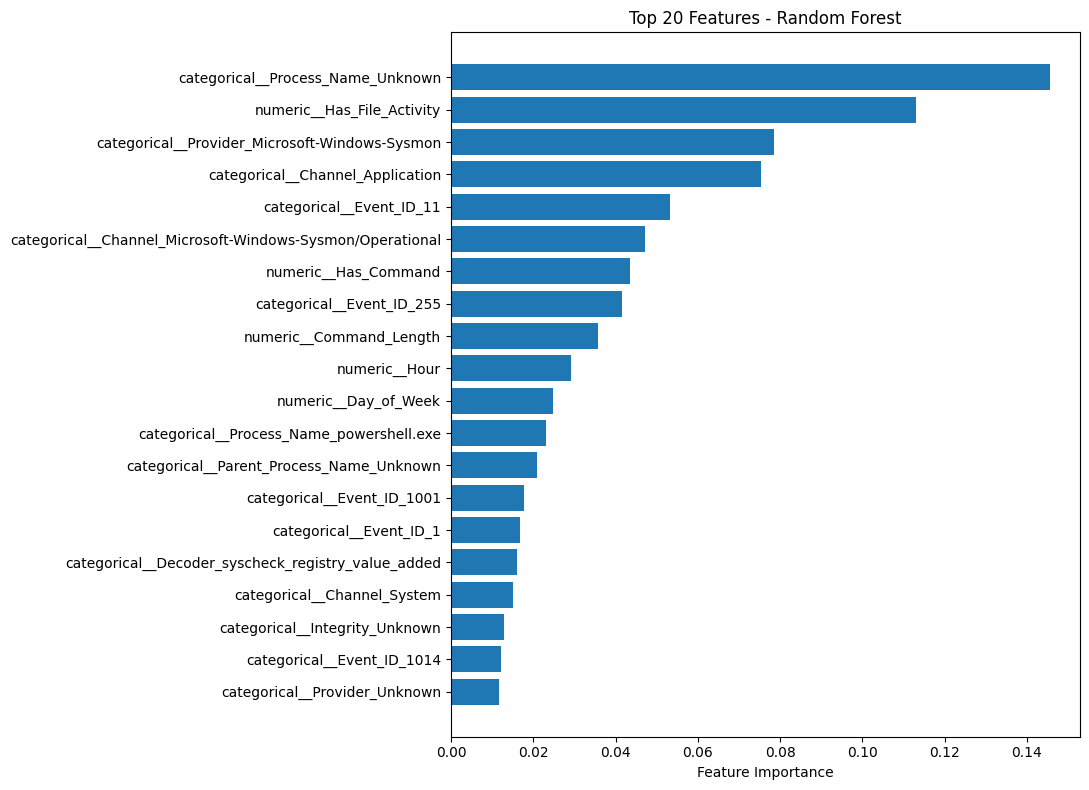

Feature importance saved successfully.


In [21]:

import pandas as pd
import matplotlib.pyplot as plt

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_features = importance_df.head(20)

display(top_features)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Top 20 Features - Random Forest")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully.")


**Investigate Potential Label Leakage**

In [22]:

import pandas as pd
import numpy as np

audit_df = pd.DataFrame({
    "Target": y,
    "Source_CSV": df["Source_CSV"].astype(str),
    "Process_Status": np.where(
        X_model["Process_Name"] == "Unknown",
        "Unknown Process",
        "Known Process"
    ),
    "Event_ID": X_model["Event_ID"],
    "Provider": X_model["Provider"],
    "Channel": X_model["Channel"],
    "Has_File_Activity": X_model["Has_File_Activity"]
})

def category_audit(data, column, min_count=100):
    result = (
        data.groupby(column, dropna=False)
        .agg(
            Records=("Target", "size"),
            Attack_Rate=("Target", "mean")
        )
        .query("Records >= @min_count")
        .sort_values("Attack_Rate", ascending=False)
    )
    result["Attack_Rate"] *= 100
    return result.round(2)

print("1. PROCESS INFORMATION AUDIT")
display(category_audit(audit_df, "Process_Status", 1))

print("\n2. EVENT ID AUDIT - Top 15 by frequency")
display(
    category_audit(audit_df, "Event_ID", 100)
    .assign(
        Frequency=audit_df["Event_ID"].value_counts()
    )
    .sort_values("Frequency", ascending=False)
    .head(15)
)

print("\n3. PROVIDER AUDIT")
display(category_audit(audit_df, "Provider", 100))

print("\n4. CHANNEL AUDIT")
display(category_audit(audit_df, "Channel", 100))

print("\n5. FILE ACTIVITY AUDIT")
display(category_audit(audit_df, "Has_File_Activity", 1))

print("\n6. SOURCE FILE AUDIT")
source_audit = (
    audit_df.groupby("Source_CSV")
    .agg(
        Records=("Target", "size"),
        Attack_Rate=("Target", "mean")
    )
    .sort_values("Attack_Rate", ascending=False)
)
source_audit["Attack_Rate"] *= 100
display(source_audit.round(2))

print("\nAudit completed.")


1. PROCESS INFORMATION AUDIT


,Records,Attack_Rate
Process_Status,,
Known Process,52932,99.11
Unknown Process,49037,22.66



2. EVENT ID AUDIT - Top 15 by frequency


,Records,Attack_Rate,Frequency
Event_ID,,,
11,22980,99.14,22980
1,20814,99.44,20814
1001,14535,0.00,14535
Unknown,11368,73.66,11368
255,5842,0.00,5842
1014,4682,0.00,4682
7,4112,99.03,4112
4624,3472,99.65,3472
10,2479,98.06,2479



3. PROVIDER AUDIT


,Records,Attack_Rate
Provider,,
Microsoft-Windows-Security-Auditing,3875,92.28
Microsoft-Windows-Sysmon,57634,89.20
Unknown,11368,73.66
Microsoft-Windows-Winlogon,199,14.57
Service Control Manager,1307,7.73
Application Error,2061,0.00
Microsoft-Windows-DistributedCOM,581,0.00
Microsoft-Windows-DNS-Client,3935,0.00
ESENT,356,0.00


... (3 outputs left out)

,Records,Attack_Rate
Has_File_Activity,,
1,31144,99.29
0,70825,46.10



6. SOURCE FILE AUDIT


,Records,Attack_Rate
Source_CSV,,
30-November.csv,2002,88.96
23-30-November.csv,8034,79.56
01-03-December.csv,8836,78.12
1-11-November.csv,8799,78.10
10-December-P2.csv,1188,72.31
07-10-December.csv,9181,72.09
04-07-December.csv,7748,71.14
03-04-December.csv,7291,66.77
14-17-December.csv,5638,61.64



Audit completed.


**Robustness Experiment (Feature Ablation)**

In [23]:

import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier
from scipy.sparse import issparse

print("Starting feature ablation experiment...")

# Remove potentially dominant telemetry-context features
reduced_categorical = [
    "Integrity", "Logon_Type", "Protocol", "Decoder", "Event_Type"
]

reduced_numeric = [
    "Hour", "Day_of_Week", "Command_Length",
    "Destination_Port", "Source_Port",
    "Has_Command", "Has_Network_Activity",
    "Has_Registry_Activity", "Has_DNS_Activity",
    "Suspicious_Term_Count"
]

X_reduced = X_model[reduced_categorical + reduced_numeric].copy()

reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         reduced_categorical),
        ("numeric", StandardScaler(), reduced_numeric)
    ]
)

X_reduced_train = reduced_preprocessor.fit_transform(
    X_reduced.loc[train_mask]
)
X_reduced_test = reduced_preprocessor.transform(
    X_reduced.loc[test_mask]
)

X_reduced_train_dense = (
    X_reduced_train.toarray()
    if issparse(X_reduced_train)
    else X_reduced_train
)

X_reduced_test_dense = (
    X_reduced_test.toarray()
    if issparse(X_reduced_test)
    else X_reduced_test
)

print("Original encoded features:", X_train_processed.shape[1])
print("Reduced encoded features:", X_reduced_train.shape[1])

ablation_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced",
        random_state=SEED, solver="liblinear"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=18, min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=SEED, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=7, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.85,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150, max_leaf_nodes=31,
        learning_rate=0.08, l2_regularization=1.0,
        class_weight="balanced", random_state=SEED
    ),
    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(128, 64), activation="relu",
        solver="adam", batch_size=512, max_iter=30,
        early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=5, random_state=SEED
    )
}

ablation_results = []

for name, model in ablation_models.items():

    print(f"\nTraining reduced {name}...")
    start = time.time()

    if name == "HistGradientBoosting":
        model.fit(X_reduced_train_dense, y_train)
        scores = model.predict_proba(X_reduced_test_dense)[:, 1]
    else:
        model.fit(X_reduced_train, y_train)
        scores = model.predict_proba(X_reduced_test)[:, 1]

    elapsed = time.time() - start
    predictions = (scores >= 0.5).astype(int)

    ablation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores),
        "Training_Time_sec": elapsed
    })

    print(f"{name} completed in {elapsed:.2f} seconds.")

ablation_df = pd.DataFrame(ablation_results)

comparison = results_df[
    ["Model", "F1-Score", "ROC-AUC"]
].merge(
    ablation_df[["Model", "F1-Score", "ROC-AUC"]],
    on="Model",
    suffixes=("_Original", "_Reduced")
)

comparison["F1_Drop"] = (
    comparison["F1-Score_Original"] -
    comparison["F1-Score_Reduced"]
)

print("\nROBUSTNESS COMPARISON")
display(comparison.round(4))

ablation_df.to_csv(
    OUTPUT_DIR / "feature_ablation_results.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "robustness_comparison.csv",
    index=False
)

print("\nAblation experiment completed and saved.")


Starting feature ablation experiment...
Original encoded features: 321
Reduced encoded features: 46

Training reduced Logistic Regression...
Logistic Regression completed in 1.07 seconds.

Training reduced Random Forest...
Random Forest completed in 9.26 seconds.

Training reduced XGBoost...
XGBoost completed in 2.48 seconds.

Training reduced HistGradientBoosting...
HistGradientBoosting completed in 6.06 seconds.

Training reduced MLP Neural Network...
MLP Neural Network completed in 22.03 seconds.

ROBUSTNESS COMPARISON


,Model,F1-Score_Original,ROC-AUC_Original,F1-Score_Reduced,ROC-AUC_Reduced,F1_Drop
0,MLP Neural Network,0.9986,0.9999,0.7746,0.8519,0.2240
1,Logistic Regression,0.9985,0.9997,0.7398,0.8152,0.2587
2,XGBoost,0.9983,0.9997,0.7224,0.8098,0.2758
3,HistGradientBoosting,0.9980,0.9998,0.7169,0.8081,0.2811
4,Random Forest,0.9965,0.9997,0.7609,0.8369,0.2356



Ablation experiment completed and saved.


**Context vs. Behavior Baseline**

In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, precision_score,
    recall_score, roc_auc_score, average_precision_score
)
import pandas as pd
import time

context_cols = [
    "Event_ID", "Provider", "Channel", "Integrity",
    "Logon_Type", "Decoder", "Event_Type",
    "Process_Name", "Parent_Process_Name"
]

behavior_cols = [
    "Hour", "Day_of_Week", "Command_Length",
    "Destination_Port", "Source_Port",
    "Has_Command", "Has_Network_Activity",
    "Has_File_Activity", "Has_Registry_Activity",
    "Has_DNS_Activity", "Suspicious_Term_Count"
]

experiments = {
    "Context Only": context_cols,
    "Behavior Only": behavior_cols
}

diagnostic_results = []

for experiment_name, columns in experiments.items():

    print(f"\nTraining {experiment_name} model...")

    categorical = [
        c for c in columns
        if c in categorical_columns
    ]
    numeric = [
        c for c in columns
        if c in numeric_columns
    ]

    transformer = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numeric)
    ])

    pipeline = Pipeline([
        ("preprocessor", transformer),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=SEED
        ))
    ])

    start = time.time()

    pipeline.fit(
        X_train_model[columns],
        y_train
    )

    scores = pipeline.predict_proba(
        X_test_model[columns]
    )[:, 1]

    predictions = (scores >= 0.5).astype(int)

    diagnostic_results.append({
        "Experiment": experiment_name,
        "Features": len(columns),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores),
        "Training_Time_sec": time.time() - start
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("\nCONTEXT VS BEHAVIOR RESULTS")
display(diagnostic_df.round(4))

diagnostic_df.to_csv(
    OUTPUT_DIR / "context_vs_behavior_results.csv",
    index=False
)

print("Diagnostic experiment saved.")



Training Context Only model...

Training Behavior Only model...

CONTEXT VS BEHAVIOR RESULTS


,Experiment,Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Training_Time_sec
0,Context Only,9,0.9983,0.9992,0.9976,0.9984,0.9999,0.9998,1.5302
1,Behavior Only,11,0.8344,0.9977,0.6835,0.8112,0.8588,0.9011,1.3456


Diagnostic experiment saved.


**Build the APT Investigation Dataset**

In [25]:

# Use the test records for investigation
test_indices = X_test_model.index

investigation_df = pd.DataFrame(index=test_indices)

# Original event information
investigation_df["Timestamp"] = pd.to_datetime(
    df.loc[test_indices, "_source.@timestamp"],
    format="%b %d, %Y @ %H:%M:%S.%f",
    errors="coerce",
    utc=True
)

investigation_df["Source_CSV"] = df.loc[test_indices, "Source_CSV"]

investigation_df["Scenario_ID"] = (
    df.loc[test_indices, "Scenario_ID"]
    if "Scenario_ID" in df.columns
    else "Unknown"
)

investigation_df["MITRE_Technique"] = (
    df.loc[test_indices, "MITRE_Technique"]
    if "MITRE_Technique" in df.columns
    else ""
)

# Engineered event information
for col in [
    "Event_ID", "Process", "Parent_Process",
    "User", "Command", "Destination_IP",
    "Destination_Port", "Event_Type"
]:
    if col in features.columns:
        investigation_df[col] = features.loc[test_indices, col]

# Weak target label
investigation_df["Weak_Label"] = y_test

# MLP predictions and confidence scores
investigation_df["MLP_Score"] = (
    model_predictions["MLP Neural Network"]["scores"]
)

investigation_df["MLP_Prediction"] = (
    model_predictions["MLP Neural Network"]["predictions"]
)

# Investigation priority
investigation_df["Priority"] = np.select(
    [
        investigation_df["MLP_Score"] >= 0.90,
        investigation_df["MLP_Score"] >= 0.70,
        investigation_df["MLP_Score"] >= 0.50
    ],
    ["High", "Medium", "Low"],
    default="Very Low"
)

# Sort events chronologically
investigation_df = investigation_df.sort_values(
    "Timestamp"
)

# Save complete investigation dataset
investigation_df.to_csv(
    OUTPUT_DIR / "apt_investigation_dataset.csv",
    index=False
)

print("APT Investigation Dataset created.")
print("Total records:", len(investigation_df))
print("\nPriority distribution:")
display(investigation_df["Priority"].value_counts())

print("\nSample investigation records:")
display(investigation_df.head(10))

print("\nSaved successfully.")


APT Investigation Dataset created.
Total records: 22955

Priority distribution:


,count
Priority,
High,11746
Very Low,11019
Low,96
Medium,94



Sample investigation records:


,Timestamp,Source_CSV,Scenario_ID,MITRE_Technique,Event_ID,Process,Parent_Process,User,Command,Destination_IP,Destination_Port,Event_Type,Weak_Label,MLP_Score,MLP_Prediction,Priority
70405,2024-12-11 20:30:03.443000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
70406,2024-12-11 20:30:03.679000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
72523,2024-12-11 20:30:03.904000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
70407,2024-12-11 20:30:04.113000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
70408,2024-12-11 20:30:04.477000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
70409,2024-12-11 20:30:04.936000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
72524,2024-12-11 20:30:05.509000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
68323,2024-12-11 20:30:05.595000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
68324,2024-12-11 20:30:05.670000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low
68325,2024-12-11 20:30:05.754000+00:00,12-13-December.csv,S28,,1001,,,,,Unknown,-1.0,,0,0.000035,0,Very Low



Saved successfully.


**Attack Investigation & Timeline**

In [26]:

# CELL 24 — High-Priority Investigation Overview

high_priority = investigation_df[
    investigation_df["Priority"] == "High"
].copy()

print("=" * 60)
print("HIGH-PRIORITY INVESTIGATION OVERVIEW")
print("=" * 60)

print("\nTotal High-Priority Events:", len(high_priority))

print("\nTop Scenarios:")
display(
    high_priority["Scenario_ID"]
    .fillna("Unassigned")
    .value_counts()
    .head(10)
    .to_frame("Event_Count")
)

print("\nTop MITRE Techniques:")
techniques = (
    high_priority["MITRE_Technique"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(15)
)
display(techniques.to_frame("Event_Count"))

print("\nTop Event IDs:")
display(
    high_priority["Event_ID"]
    .value_counts()
    .head(15)
    .to_frame("Event_Count")
)

print("\nTop Processes:")
display(
    high_priority["Process"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(15)
    .to_frame("Event_Count")
)


HIGH-PRIORITY INVESTIGATION OVERVIEW

Total High-Priority Events: 11746

Top Scenarios:


,Event_Count
Scenario_ID,
S34,4536
S35,2819
S07,2669
S33,666
S28,574
S32,223
S16,135
S08,88
S18,29



Top MITRE Techniques:


,Event_Count
MITRE_Technique,
"[""T1105""]",2210
"[""T1078""]",1647
"[""T1059.003""]",1184
"[""T1053.005""]",1026
"[""T1112""]",930
"[""T1055""]",844
"[""T1087""]",668
"[""T1087"",""T1059.003""]",524
"[""T1059"",""T1105""]",520



Top Event IDs:


,Event_Count
Event_ID,
1,3396
11,2873
4624,1648
Unknown,1476
7,1166
10,826
13,245
4625,44
7045,38



Top Processes:


,Event_Count
Process,
C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,1988
C:\\Windows\\System32\\services.exe,1566
C:\\Windows\\System32\\cmd.exe,1286
C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,400
C:\\Windows\\SystemApps\\Microsoft.Windows.Search_cw5n1h2txyewy\\SearchApp.exe,323
C:\\Windows\\System32\\net.exe,280
C:\\Windows\\System32\\net1.exe,271
C:\\Windows\\System32\\svchost.exe,263
C:\\Windows\\System32\\sppsvc.exe,244


**Scenario Attack Timeline**

In [27]:

# CELL 25 — Scenario S34 Attack Timeline

import ast

scenario_id = "S34"

timeline = high_priority[
    high_priority["Scenario_ID"].astype(str) == scenario_id
].copy()

timeline["Timestamp"] = pd.to_datetime(
    timeline["Timestamp"], errors="coerce", utc=True
)

def parse_techniques(value):
    if pd.isna(value) or str(value).strip() == "":
        return []
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, list):
            return parsed
        return [str(parsed)]
    except (ValueError, SyntaxError):
        return [str(value)]

timeline["MITRE_Techniques"] = timeline[
    "MITRE_Technique"
].apply(parse_techniques)

timeline = timeline.sort_values("Timestamp")

timeline_columns = [
    "Timestamp", "Source_CSV", "Event_ID",
    "Process", "Parent_Process", "User",
    "Command", "Destination_IP", "Destination_Port",
    "MITRE_Techniques", "MLP_Score", "Priority"
]

timeline_columns = [
    col for col in timeline_columns if col in timeline.columns
]

print("SCENARIO:", scenario_id)
print("Total High-Priority Events:", len(timeline))
print("Time Range:")
print("Start:", timeline["Timestamp"].min())
print("End:  ", timeline["Timestamp"].max())

print("\nChronological Timeline — First 100 Events")
display(timeline[timeline_columns].head(100))

# Save the complete timeline
timeline[timeline_columns].to_csv(
    OUTPUT_DIR / f"{scenario_id}_attack_timeline.csv",
    index=False
)

# Count individual techniques, including multi-technique records
from collections import Counter

technique_counts = Counter(
    technique
    for techniques in timeline["MITRE_Techniques"]
    for technique in techniques
)

print("\nIndividual MITRE Technique Counts:")
display(
    pd.DataFrame(
        technique_counts.most_common(20),
        columns=["MITRE_Technique", "Event_Count"]
    )
)

print("\nTimeline saved successfully.")


SCENARIO: S34
Total High-Priority Events: 4536
Time Range:
Start: 2024-12-12 07:06:28.593000+00:00
End:   2024-12-22 12:56:36.391000+00:00

Chronological Timeline — First 100 Events


,Timestamp,Source_CSV,Event_ID,Process,Parent_Process,User,Command,Destination_IP,Destination_Port,MITRE_Techniques,MLP_Score,Priority
73368,2024-12-12 07:06:28.593000+00:00,12-13-December.csv,1,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,Unknown,-1.0,[T1087],0.999981,High
71203,2024-12-12 07:06:31.987000+00:00,12-13-December.csv,1,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,Unknown,-1.0,[T1087],0.999979,High
71204,2024-12-12 07:06:32.022000+00:00,12-13-December.csv,1,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,Unknown,-1.0,[T1087],0.999981,High
73373,2024-12-12 07:06:32.893000+00:00,12-13-December.csv,1,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,Unknown,-1.0,[T1087],0.999979,High
69445,2024-12-12 07:06:32.924000+00:00,12-13-December.csv,1,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,Unknown,-1.0,[T1087],0.999981,High
...,...,...,...,...,...,...,...,...,...,...,...,...
69580,2024-12-12 09:40:12.632000+00:00,12-13-December.csv,11,C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0...,,DESKTOP-QGB4EQH\\mari,,Unknown,-1.0,[T1105],0.999946,High
71366,2024-12-12 09:40:17.360000+00:00,12-13-December.csv,13,C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0...,,DESKTOP-QGB4EQH\\mari,,Unknown,-1.0,"[T1548.002, T1112]",0.999250,High
73833,2024-12-12 09:40:17.470000+00:00,12-13-December.csv,1,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,c:\\windows\\system32\\cmd.exe /c cd /d C:\\U...,Unknown,-1.0,"[T1087, T1059.003]",0.999999,High
71367,2024-12-12 09:40:18.627000+00:00,12-13-December.csv,11,C:\\WINDOWS\\system32\\cmd.exe,,DESKTOP-QGB4EQH\\mari,,Unknown,-1.0,"[T1059, T1105]",0.999982,High



Individual MITRE Technique Counts:


,MITRE_Technique,Event_Count
0,T1105,2107
1,T1087,1240
2,T1112,697
3,T1059.003,524
4,T1059,360
5,T1070.004,154
6,T1543.003,151
7,T1565.001,139
8,T1027.004,106
9,T1548.002,60



Timeline saved successfully.


**Detecting Activity Episodes**

In [28]:

# CELL 26 — Split Scenario S34 into Activity Episodes

EPISODE_GAP_MINUTES = 30

episodes_df = timeline.copy()
episodes_df = episodes_df.sort_values("Timestamp").reset_index(drop=True)

# Calculate time difference between consecutive events
episodes_df["Gap_Minutes"] = (
    episodes_df["Timestamp"].diff().dt.total_seconds() / 60
)

# Start a new episode when the inactivity gap exceeds 30 minutes
episodes_df["New_Episode"] = (
    episodes_df["Gap_Minutes"].isna() |
    (episodes_df["Gap_Minutes"] > EPISODE_GAP_MINUTES)
)

episodes_df["Episode_ID"] = (
    episodes_df["New_Episode"].cumsum()
)

# Summarize each episode
episode_summaries = []

for episode_id, group in episodes_df.groupby("Episode_ID"):
    all_techniques = sorted(set(
        technique
        for techniques in group["MITRE_Techniques"]
        for technique in techniques
    ))

    processes = (
        group["Process"]
        .replace("", np.nan)
        .dropna()
        .nunique()
    )

    episode_summaries.append({
        "Episode_ID": int(episode_id),
        "Start_Time": group["Timestamp"].min(),
        "End_Time": group["Timestamp"].max(),
        "Duration_Minutes": round(
            (group["Timestamp"].max() - group["Timestamp"].min())
            .total_seconds() / 60, 2
        ),
        "Event_Count": len(group),
        "Unique_Processes": processes,
        "Unique_Event_IDs": group["Event_ID"].nunique(),
        "MITRE_Techniques": all_techniques
    })

episode_summary_df = pd.DataFrame(episode_summaries)

episode_summary_df = episode_summary_df.sort_values(
    "Event_Count", ascending=False
)

print("SCENARIO:", scenario_id)
print("Inactivity Gap Threshold:", EPISODE_GAP_MINUTES, "minutes")
print("Total Episodes Detected:", len(episode_summary_df))

print("\nLargest 15 Activity Episodes:")
display(episode_summary_df.head(15))

print("\nEpisode Size Statistics:")
display(
    episode_summary_df["Event_Count"].describe().to_frame(
        "Event_Count"
    )
)

# Save episode analysis
episode_summary_df.to_csv(
    OUTPUT_DIR / f"{scenario_id}_episode_summary.csv",
    index=False
)

episodes_df.to_csv(
    OUTPUT_DIR / f"{scenario_id}_events_with_episodes.csv",
    index=False
)

print("\nEpisode analysis saved successfully.")


SCENARIO: S34
Inactivity Gap Threshold: 30 minutes
Total Episodes Detected: 20

Largest 15 Activity Episodes:


,Episode_ID,Start_Time,End_Time,Duration_Minutes,Event_Count,Unique_Processes,Unique_Event_IDs,MITRE_Techniques
5,6,2024-12-12 22:58:10.096000+00:00,2024-12-13 03:52:37.005000+00:00,294.45,1260,40,5,"[T1027.004, T1059, T1059.001, T1059.003, T1070..."
7,8,2024-12-13 11:22:43.499000+00:00,2024-12-13 15:37:33.820000+00:00,254.84,1117,41,3,"[T1027.004, T1059, T1059.001, T1059.003, T1070..."
1,2,2024-12-12 09:34:17.726000+00:00,2024-12-12 12:25:43.660000+00:00,171.43,395,29,4,"[T1027.004, T1059, T1059.001, T1059.003, T1070..."
8,9,2024-12-13 23:22:35.367000+00:00,2024-12-13 23:23:26.505000+00:00,0.85,380,3,3,"[T1059, T1070.004, T1087, T1105, T1112, T1485,..."
6,7,2024-12-13 07:09:02.877000+00:00,2024-12-13 10:05:12.394000+00:00,176.16,348,33,3,"[T1027.004, T1059, T1059.001, T1059.003, T1070..."
4,5,2024-12-12 20:48:58.705000+00:00,2024-12-12 22:01:47.498000+00:00,72.81,124,14,3,"[T1027.004, T1059, T1059.003, T1070.004, T1087..."
15,16,2024-12-16 06:16:45.169000+00:00,2024-12-16 06:53:10.288000+00:00,36.42,119,13,4,"[T1027.004, T1059, T1059.003, T1070.004, T1087..."
11,12,2024-12-14 17:17:29.183000+00:00,2024-12-14 17:32:58.750000+00:00,15.49,114,14,3,"[T1027.004, T1059, T1059.001, T1059.003, T1070..."
12,13,2024-12-15 06:39:07.962000+00:00,2024-12-15 07:03:58.139000+00:00,24.84,96,10,3,"[T1027.004, T1059, T1059.003, T1070.004, T1087..."
18,19,2024-12-22 10:29:28.940000+00:00,2024-12-22 11:17:58.715000+00:00,48.50,95,15,5,"[T1027.004, T1059, T1070.004, T1087, T1105, T1..."



Episode Size Statistics:


,Event_Count
count,20.000000
mean,226.800000
std,349.396713
min,5.000000
25%,55.000000
50%,91.000000
75%,180.000000
max,1260.000000



Episode analysis saved successfully.


**Detailed Investigation of Episode 6**

In [29]:

# CELL 27 — Detailed Analysis of Episode 6

selected_episode = 6

episode_data = episodes_df[
    episodes_df["Episode_ID"] == selected_episode
].copy().sort_values("Timestamp")

print("=" * 65)
print(f"DETAILED INVESTIGATION — S34 / EPISODE {selected_episode}")
print("=" * 65)

print("\n1. Event ID Distribution")
display(
    episode_data["Event_ID"]
    .value_counts()
    .rename_axis("Event_ID")
    .to_frame("Count")
)

print("\n2. Most Frequent Processes")
display(
    episode_data["Process"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(15)
    .rename_axis("Process")
    .to_frame("Count")
)

print("\n3. Most Frequent Parent Processes")
display(
    episode_data["Parent_Process"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(10)
    .rename_axis("Parent_Process")
    .to_frame("Count")
)

print("\n4. Individual MITRE Technique Distribution")
episode_technique_counts = Counter(
    technique
    for techniques in episode_data["MITRE_Techniques"]
    for technique in techniques
)

display(
    pd.DataFrame(
        episode_technique_counts.most_common(),
        columns=["MITRE_Technique", "Event_Count"]
    )
)

print("\n5. User Distribution")
display(
    episode_data["User"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(10)
    .rename_axis("User")
    .to_frame("Count")
)

print("\n6. Chronological Event Samples")
sample_columns = [
    "Timestamp", "Event_ID", "Process", "Parent_Process",
    "User", "Command", "MITRE_Techniques", "MLP_Score"
]
sample_columns = [
    col for col in sample_columns if col in episode_data.columns
]

display(episode_data[sample_columns].head(50))

# Save complete episode investigation
episode_data[sample_columns].to_csv(
    OUTPUT_DIR / "S34_Episode_6_Detailed_Investigation.csv",
    index=False
)

print("\nComplete Episode 6 investigation saved.")


DETAILED INVESTIGATION — S34 / EPISODE 6

1. Event ID Distribution


,Count
Event_ID,
11,620
1,321
Unknown,314
13,4
7,1



2. Most Frequent Processes


,Count
Process,
C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,541
C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,74
C:\\Windows\\System32\\net1.exe,54
C:\\WINDOWS\\system32\\cmd.exe,37
C:\\Users\\Public\\splunkd.exe,28
C:\\Windows\\System32\\sc.exe,26
C:\\Windows\\Microsoft.NET\\Framework64\\v4.0.30319\\csc.exe,20
C:\\Windows\\System32\\cmd.exe,18
C:\\Windows\\System32\\curl.exe,17



3. Most Frequent Parent Processes


,Count
Parent_Process,
C:\\Windows\\System32\\cmd.exe,162
C:\\Windows\\System32\\net.exe,54
C:\\Users\\Public\\splunkd.exe,52
C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,36
C:\\Program Files (x86)\\ossec-agent\\wazuh-agent.exe,16
C:\\Windows\\System32\\CompatTelRunner.exe,1


... (3 outputs left out)

,Count
User,
DESKTOP-QGB4EQH\\mari,929
NT AUTHORITY\\SYSTEM,17



6. Chronological Event Samples


,Timestamp,Event_ID,Process,Parent_Process,User,Command,MITRE_Techniques,MLP_Score
650,2024-12-12 22:58:10.096000+00:00,11,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,,DESKTOP-QGB4EQH\\mari,,[T1105],0.996353
651,2024-12-12 22:58:23.627000+00:00,11,C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0...,,DESKTOP-QGB4EQH\\mari,,[T1105],0.996353
652,2024-12-12 23:11:57.713000+00:00,1,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmdkey.exe /list,"[T1087, T1059.003]",0.999058
653,2024-12-12 23:11:57.714000+00:00,1,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992523
654,2024-12-12 23:11:57.743000+00:00,1,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,"C:\\WINDOWS\\system32\\net1 localgroup \""Users\""",[T1087],0.992447
655,2024-12-12 23:11:57.775000+00:00,1,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 localgroup,[T1087],0.992494
656,2024-12-12 23:12:46.911000+00:00,11,C:\\WINDOWS\\System32\\WindowsPowerShell\\v1.0...,,DESKTOP-QGB4EQH\\mari,,[T1105],0.993559
657,2024-12-12 23:12:50.529000+00:00,1,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" user","[T1087, T1059.001]",0.983522
658,2024-12-12 23:12:51.602000+00:00,1,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992527
659,2024-12-12 23:13:04.724000+00:00,1,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" localgroup","[T1087, T1059.001]",0.983664



Complete Episode 6 investigation saved.


**Command and Process Relationship Analysis**

In [30]:

# CELL 28 — Command and Process Relationship Analysis

# 1. Extract records containing actual commands
command_events = episode_data.copy()

command_events["Command_Clean"] = (
    command_events["Command"]
    .fillna("")
    .astype(str)
    .str.strip()
)

command_events = command_events[
    command_events["Command_Clean"] != ""
].copy()

print("=" * 65)
print("COMMAND AND PROCESS RELATIONSHIP ANALYSIS")
print("=" * 65)

print("\n1. Command Statistics")
print("Events with commands:", len(command_events))
print("Unique commands:", command_events["Command_Clean"].nunique())

print("\n2. Chronological Command Samples")

command_columns = [
    "Timestamp", "Process", "Parent_Process",
    "User", "Command_Clean", "MITRE_Techniques", "MLP_Score"
]

if "Target_File" in command_events.columns:
    command_columns.insert(5, "Target_File")

command_columns = [
    col for col in command_columns
    if col in command_events.columns
]

display(
    command_events[command_columns]
    .sort_values("Timestamp")
    .head(60)
)

# 3. Parent-child process relationships
process_pairs = (
    episode_data[
        (episode_data["Process"].fillna("").str.strip() != "") &
        (episode_data["Parent_Process"].fillna("").str.strip() != "")
    ]
    .groupby(["Parent_Process", "Process"])
    .size()
    .reset_index(name="Event_Count")
    .sort_values("Event_Count", ascending=False)
)

print("\n3. Most Frequent Parent → Child Relationships")
display(process_pairs.head(20))

# 4. Five-minute event activity
activity = (
    episode_data.set_index("Timestamp")
    .resample("5min")
    .size()
    .rename("Event_Count")
    .reset_index()
)

print("\n4. Five-Minute Activity Peaks")
display(
    activity.sort_values("Event_Count", ascending=False).head(15)
)

# 5. Commands containing potentially relevant investigation terms
keywords = [
    "powershell", "curl", "bitsadmin", "certutil",
    "cmdkey", "net user", "net localgroup",
    "schtasks", "reg add", "reg delete",
    "sc create", "wscript", "rundll32",
    "regsvr32", "download", "http"
]

pattern = "|".join(keywords)

relevant_commands = command_events[
    command_events["Command_Clean"].str.contains(
        pattern, case=False, regex=True, na=False
    )
].copy()

print("\n5. Commands Matching Investigation Keywords")
print("Matching records:", len(relevant_commands))

display(
    relevant_commands[
        command_columns
    ].sort_values("Timestamp").head(60)
)

# Save analysis outputs
command_events[command_columns].to_csv(
    OUTPUT_DIR / "S34_Episode_6_Command_Events.csv",
    index=False
)

process_pairs.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Process_Relationships.csv",
    index=False
)

activity.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Activity_By_5min.csv",
    index=False
)

print("\nCommand and process analysis saved successfully.")


COMMAND AND PROCESS RELATIONSHIP ANALYSIS

1. Command Statistics
Events with commands: 321
Unique commands: 118

2. Chronological Command Samples


,Timestamp,Process,Parent_Process,User,Command_Clean,MITRE_Techniques,MLP_Score
652,2024-12-12 23:11:57.713000+00:00,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmdkey.exe /list,"[T1087, T1059.003]",0.999058
653,2024-12-12 23:11:57.714000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992523
654,2024-12-12 23:11:57.743000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,"C:\\WINDOWS\\system32\\net1 localgroup \""Users\""",[T1087],0.992447
655,2024-12-12 23:11:57.775000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 localgroup,[T1087],0.992494
657,2024-12-12 23:12:50.529000+00:00,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" user","[T1087, T1059.001]",0.983522
658,2024-12-12 23:12:51.602000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992527
659,2024-12-12 23:13:04.724000+00:00,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" localgroup","[T1087, T1059.001]",0.983664
660,2024-12-12 23:13:04.731000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 localgroup,[T1087],0.992499
662,2024-12-12 23:15:19.898000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmd /r cmd,"[T1087, T1059.003]",0.999882
664,2024-12-12 23:16:06.921000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,c:\\windows\\system32\\cmd.exe /c cd /d C:\\U...,"[T1087, T1059.003]",0.999762



3. Most Frequent Parent → Child Relationships


,Parent_Process,Process,Event_Count
39,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\net1.exe,54
1,C:\\Users\\Public\\splunkd.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,52
29,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\sc.exe,26
3,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Windows\\Microsoft.NET\\Framework64\\v4.0....,18
19,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,18
22,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\curl.exe,17
0,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,C:\\Windows\\SysWOW64\\net.exe,16
5,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Windows\\System32\\net.exe,12
36,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\wscript.exe,10
16,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,8



4. Five-Minute Activity Peaks


,Timestamp,Event_Count
58,2024-12-13 03:45:00+00:00,247
59,2024-12-13 03:50:00+00:00,67
4,2024-12-12 23:15:00+00:00,40
20,2024-12-13 00:35:00+00:00,37
16,2024-12-13 00:15:00+00:00,35
31,2024-12-13 01:30:00+00:00,30
14,2024-12-13 00:05:00+00:00,30
5,2024-12-12 23:20:00+00:00,30
11,2024-12-12 23:50:00+00:00,29
19,2024-12-13 00:30:00+00:00,29



5. Commands Matching Investigation Keywords
Matching records: 128


,Timestamp,Process,Parent_Process,User,Command_Clean,MITRE_Techniques,MLP_Score
652,2024-12-12 23:11:57.713000+00:00,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmdkey.exe /list,"[T1087, T1059.003]",0.999058
666,2024-12-12 23:16:08.475000+00:00,C:\\Windows\\System32\\wscript.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\System32\\WScript.exe\"" \""C:\\U...",[T1059],0.998012
669,2024-12-12 23:16:51.810000+00:00,C:\\Windows\\System32\\curl.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,"C:\\Windows\\System32\\Curl.exe -s -A \""HttpB...","[T1087, T1059.003]",0.999945
673,2024-12-12 23:17:20.818000+00:00,C:\\Windows\\System32\\curl.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,"C:\\Windows\\System32\\Curl.exe -s -A \""HttpB...","[T1087, T1059.003]",0.999945
675,2024-12-12 23:17:22.837000+00:00,C:\\Windows\\System32\\curl.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,"C:\\Windows\\System32\\Curl.exe -s -A \""Wget/...","[T1087, T1059.003]",0.999942
678,2024-12-12 23:17:38.787000+00:00,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmdkey.exe /list,"[T1087, T1059.003]",0.999058
715,2024-12-12 23:21:48.377000+00:00,C:\\Windows\\System32\\wscript.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\System32\\WScript.exe\"" \""C:\\U...",[T1059],0.998012
726,2024-12-12 23:24:36.389000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,DESKTOP-QGB4EQH\\mari,"powershell.exe -ExecutionPolicy Bypass -C \""$u...",[T1070.004],0.998890
740,2024-12-12 23:26:33.303000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,DESKTOP-QGB4EQH\\mari,"powershell.exe -ExecutionPolicy Bypass -C \""Ne...",[T1070.004],0.999221
742,2024-12-12 23:26:38.880000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,DESKTOP-QGB4EQH\\mari,"powershell.exe -ExecutionPolicy Bypass -C \""Ne...",[T1070.004],0.999221



Command and process analysis saved successfully.


**Constructing an organized Attack Timeline**

In [33]:
# ============================================================
# APT INVESTIGATION TIMELINE
# ============================================================

# Add host information from the original dataset
timeline["_source.agent.name"] = df.loc[
    timeline.index, "_source.agent.name"
]

timeline["_source.agent.id"] = df.loc[
    timeline.index, "_source.agent.id"
]

# Rename for readability
timeline = timeline.rename(columns={
    "_source.agent.name": "Host_Name",
    "_source.agent.id": "Host_ID"
})

# Arrange columns
investigation_columns = [
    "Timestamp",
    "Host_Name",
    "Host_ID",
    "Source_CSV",
    "Process",
    "Parent_Process",
    "User",
    "Command",
    "MITRE_Technique",
    "Scenario_ID",
    "Derived_Label",
    "Target",
    "MLP_Prediction",
    "MLP_Score"
]

timeline = timeline[
    [c for c in investigation_columns if c in timeline.columns]
].sort_values("Timestamp")

# Save timeline
timeline.to_csv(
    OUTPUT_DIR / "apt_investigation_timeline.csv",
    index=False
)

print("=" * 65)
print("APT INVESTIGATION TIMELINE")
print("=" * 65)

print("Command events:", len(timeline))
print("Unique processes:", timeline["Process"].nunique())
print("Unique parent processes:", timeline["Parent_Process"].nunique())
print("Unique hosts:", timeline["Host_Name"].nunique())
print("Unique scenarios:", timeline["Scenario_ID"].nunique())

display(timeline.head(15))

print("\nHost distribution:")
display(timeline["Host_Name"].value_counts().head(10))

print("\nTimeline saved successfully.")

APT INVESTIGATION TIMELINE
Command events: 20893
Unique processes: 90
Unique parent processes: 34
Unique hosts: 4
Unique scenarios: 13


,Timestamp,Host_Name,Host_ID,Source_CSV,Process,Parent_Process,User,Command,MITRE_Technique,Scenario_ID,Derived_Label,Target,MLP_Prediction,MLP_Score
99454,2024-10-29 18:23:31.748000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,,,,add,,S34,untagged,0,0,0.037602
99921,2024-10-29 18:41:19.414000+00:00,Maryam,0,28-October-01-November.csv,,,,/usr/bin/systemctl restart wazuh-manager.service,"[""T1548""]",S32,technique-tagged,1,1,0.996315
99669,2024-10-29 18:44:26.547000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,"[""T1087""]",S34,technique-tagged,1,1,0.971403
99905,2024-10-29 18:44:27.655000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,"[""T1087""]",S34,technique-tagged,1,1,0.979135
99670,2024-10-29 18:44:27.668000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,"[""T1087""]",S34,technique-tagged,1,1,0.971403
99906,2024-10-29 18:44:27.668000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,"[""T1087""]",S34,technique-tagged,1,1,0.979135
99530,2024-10-29 18:44:27.700000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,"[""T1087""]",S34,technique-tagged,1,1,0.979135
99531,2024-10-29 18:44:27.701000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,"[""T1087""]",S34,technique-tagged,1,1,0.971403
99907,2024-10-29 18:44:27.731000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net.exe,C:\\Program Files (x86)\\ossec-agent\\wazuh-ag...,NT AUTHORITY\\SYSTEM,net.exe accounts,"[""T1087""]",S34,technique-tagged,1,1,0.971403
99671,2024-10-29 18:44:27.731000+00:00,DESKTOP-DS4FBF4,1,28-October-01-November.csv,C:\\Windows\\SysWOW64\\net1.exe,C:\\Windows\\SysWOW64\\net.exe,NT AUTHORITY\\SYSTEM,C:\\WINDOWS\\system32\\net1 accounts,"[""T1087""]",S34,technique-tagged,1,1,0.979135



Host distribution:


,count
Host_Name,
window-agent3,15583
wazuh-agent,4678
DESKTOP-DS4FBF4,557
Maryam,75



Timeline saved successfully.


**Preparing an Incident Timeline**

In [34]:
# ============================================================
# NEXT CELL — FOCUSED INCIDENT TIMELINE
# Scenario S34 | Episode 6
# ============================================================

incident_timeline = episode_data.copy()

# Add host information using original dataset indices
incident_timeline["Host_Name"] = df.loc[
    incident_timeline.index, "_source.agent.name"
]

incident_timeline["Host_ID"] = df.loc[
    incident_timeline.index, "_source.agent.id"
]

# Keep events with actual commands
incident_timeline["Command"] = (
    incident_timeline["Command"]
    .fillna("")
    .astype(str)
    .str.strip()
)

incident_timeline = incident_timeline[
    incident_timeline["Command"] != ""
].copy()

# Select relevant columns
incident_columns = [
    "Timestamp",
    "Host_Name",
    "Host_ID",
    "Process",
    "Parent_Process",
    "User",
    "Command",
    "MITRE_Techniques",
    "MLP_Score"
]

incident_columns = [
    col for col in incident_columns
    if col in incident_timeline.columns
]

incident_timeline = incident_timeline[
    incident_columns
].sort_values("Timestamp")

# Save focused incident
incident_timeline.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Incident_Timeline.csv",
    index=False
)

print("=" * 60)
print("FOCUSED INCIDENT TIMELINE")
print("=" * 60)

print("Scenario: S34")
print("Episode: 6")
print("Command events:", len(incident_timeline))
print("Hosts:", incident_timeline["Host_Name"].nunique())
print("Processes:", incident_timeline["Process"].nunique())

display(incident_timeline.head(20))

FOCUSED INCIDENT TIMELINE
Scenario: S34
Episode: 6
Command events: 321
Hosts: 4
Processes: 37


,Timestamp,Host_Name,Host_ID,Process,Parent_Process,User,Command,MITRE_Techniques,MLP_Score
652,2024-12-12 23:11:57.713000+00:00,window-agent3,3,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmdkey.exe /list,"[T1087, T1059.003]",0.999058
653,2024-12-12 23:11:57.714000+00:00,window-agent3,3,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992523
654,2024-12-12 23:11:57.743000+00:00,window-agent3,3,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,"C:\\WINDOWS\\system32\\net1 localgroup \""Users\""",[T1087],0.992447
655,2024-12-12 23:11:57.775000+00:00,window-agent3,3,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 localgroup,[T1087],0.992494
657,2024-12-12 23:12:50.529000+00:00,window-agent3,3,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" user","[T1087, T1059.001]",0.983522
658,2024-12-12 23:12:51.602000+00:00,window-agent3,3,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 user,[T1087],0.992527
659,2024-12-12 23:13:04.724000+00:00,window-agent3,3,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,DESKTOP-QGB4EQH\\mari,"\""C:\\WINDOWS\\system32\\net.exe\"" localgroup","[T1087, T1059.001]",0.983664
660,2024-12-12 23:13:04.731000+00:00,window-agent3,3,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,DESKTOP-QGB4EQH\\mari,C:\\WINDOWS\\system32\\net1 localgroup,[T1087],0.992499
662,2024-12-12 23:15:19.898000+00:00,window-agent3,3,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,cmd /r cmd,"[T1087, T1059.003]",0.999882
664,2024-12-12 23:16:06.921000+00:00,window-agent3,3,C:\\Windows\\System32\\cmd.exe,C:\\Windows\\System32\\cmd.exe,DESKTOP-QGB4EQH\\mari,c:\\windows\\system32\\cmd.exe /c cd /d C:\\U...,"[T1087, T1059.003]",0.999762


**Incident Evidence Summary**

In [35]:
# ============================================================
# INCIDENT EVIDENCE SUMMARY
# ============================================================

print("=" * 65)
print("1. HOST DISTRIBUTION")
print("=" * 65)

display(
    incident_timeline["Host_Name"]
    .value_counts()
    .rename("Event_Count")
    .to_frame()
)

print("\n" + "=" * 65)
print("2. MITRE TECHNIQUE DISTRIBUTION")
print("=" * 65)

technique_counts = (
    incident_timeline["MITRE_Techniques"]
    .dropna()
    .explode()
    .value_counts()
)

display(technique_counts.rename("Event_Count").to_frame())

print("\n" + "=" * 65)
print("3. PROCESS DISTRIBUTION")
print("=" * 65)

display(
    incident_timeline["Process"]
    .value_counts()
    .head(15)
    .rename("Event_Count")
    .to_frame()
)

print("\n" + "=" * 65)
print("4. USER DISTRIBUTION")
print("=" * 65)

display(
    incident_timeline["User"]
    .replace("", "Unknown")
    .value_counts()
    .head(10)
    .rename("Event_Count")
    .to_frame()
)

print("\n" + "=" * 65)
print("5. INCIDENT TIME RANGE")
print("=" * 65)

print("Start:", incident_timeline["Timestamp"].min())
print("End:", incident_timeline["Timestamp"].max())

print("\n" + "=" * 65)
print("6. MODEL SCORE SUMMARY")
print("=" * 65)

display(incident_timeline["MLP_Score"].describe())

1. HOST DISTRIBUTION


,Event_Count
Host_Name,
window-agent3,174
wazuh-agent,90
agent1,51
DESKTOP-DS4FBF4,6



2. MITRE TECHNIQUE DISTRIBUTION


,Event_Count
MITRE_Techniques,
T1087,223
T1059.003,141
T1070.004,57
T1027.004,18
T1059.001,12
T1059,11
T1105,6
T1548.002,4
T1562.004,2



3. PROCESS DISTRIBUTION


,Event_Count
Process,
C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe,61
C:\\Windows\\System32\\net1.exe,54
C:\\Windows\\System32\\sc.exe,26
C:\\Windows\\Microsoft.NET\\Framework64\\v4.0.30319\\csc.exe,20
C:\\Windows\\System32\\cmd.exe,18
C:\\Windows\\System32\\curl.exe,17
C:\\Windows\\SysWOW64\\net.exe,16
C:\\Windows\\System32\\net.exe,12
C:\\Windows\\System32\\wscript.exe,10



4. USER DISTRIBUTION


,Event_Count
User,
DESKTOP-QGB4EQH\\mari,304
NT AUTHORITY\\SYSTEM,17



5. INCIDENT TIME RANGE
Start: 2024-12-12 23:11:57.713000+00:00
End: 2024-12-13 03:41:16.429000+00:00

6. MODEL SCORE SUMMARY


,MLP_Score
count,321.000000
mean,0.998717
std,0.003322
min,0.983522
25%,0.999786
50%,0.999999
75%,1.000000
max,1.000000


**Converting events into Attack Stages**

In [36]:
# ============================================================
# INCIDENT ATTACK-STAGE EVIDENCE
# ============================================================

import re

incident_stages = incident_timeline.copy()

command_text = (
    incident_stages["Command"].fillna("").astype(str).str.lower()
)

process_text = (
    incident_stages["Process"].fillna("").astype(str).str.lower()
)

# Evidence-based stage indicators
stage_patterns = {
    "Account Discovery": r"net1?\s+(user|localgroup|accounts)|cmdkey",
    "Command and Script Execution": r"powershell|cmd\.exe|wscript|encodedcommand",
    "Possible Tool Transfer": r"curl|bitsadmin|desktopimgdownldr",
    "Service or System Modification": r"sc\.exe\s+(create|config)|netsh|regsvr32",
    "Log and Activity Management": r"wevtutil|clear-eventlog",
}

for stage, pattern in stage_patterns.items():
    incident_stages[stage] = (
        command_text.str.contains(pattern, regex=True, na=False)
        | process_text.str.contains(pattern, regex=True, na=False)
    )

# Summary: stages can overlap
stage_summary = pd.DataFrame({
    "Stage": list(stage_patterns.keys()),
    "Matching_Events": [
        int(incident_stages[stage].sum())
        for stage in stage_patterns
    ]
})

print("=" * 65)
print("INCIDENT ATTACK-STAGE EVIDENCE")
print("=" * 65)

display(stage_summary)

# Show representative evidence for each stage
for stage in stage_patterns:
    print("\n" + "=" * 65)
    print(stage)
    print("=" * 65)

    sample = incident_stages.loc[
        incident_stages[stage],
        ["Timestamp", "Host_Name", "Process", "Command"]
    ].head(5)

    display(sample)

# Save detailed evidence
incident_stages.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Attack_Stage_Evidence.csv",
    index=False
)

stage_summary.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Stage_Summary.csv",
    index=False
)

print("\nEvidence files saved successfully.")

INCIDENT ATTACK-STAGE EVIDENCE


,Stage,Matching_Events
0,Account Discovery,43
1,Command and Script Execution,101
2,Possible Tool Transfer,28
3,Service or System Modification,12
4,Log and Activity Management,6



Account Discovery


,Timestamp,Host_Name,Process,Command
652,2024-12-12 23:11:57.713000+00:00,window-agent3,C:\\Windows\\System32\\cmdkey.exe,cmdkey.exe /list
653,2024-12-12 23:11:57.714000+00:00,window-agent3,C:\\Windows\\System32\\net1.exe,C:\\WINDOWS\\system32\\net1 user
654,2024-12-12 23:11:57.743000+00:00,window-agent3,C:\\Windows\\System32\\net1.exe,"C:\\WINDOWS\\system32\\net1 localgroup \""Users\"""
655,2024-12-12 23:11:57.775000+00:00,window-agent3,C:\\Windows\\System32\\net1.exe,C:\\WINDOWS\\system32\\net1 localgroup
658,2024-12-12 23:12:51.602000+00:00,window-agent3,C:\\Windows\\System32\\net1.exe,C:\\WINDOWS\\system32\\net1 user



Command and Script Execution


,Timestamp,Host_Name,Process,Command
662,2024-12-12 23:15:19.898000+00:00,window-agent3,C:\\Windows\\System32\\cmd.exe,cmd /r cmd
664,2024-12-12 23:16:06.921000+00:00,window-agent3,C:\\Windows\\System32\\cmd.exe,c:\\windows\\system32\\cmd.exe /c cd /d C:\\U...
666,2024-12-12 23:16:08.475000+00:00,window-agent3,C:\\Windows\\System32\\wscript.exe,"\""C:\\WINDOWS\\System32\\WScript.exe\"" \""C:\\U..."
702,2024-12-12 23:20:32.030000+00:00,window-agent3,C:\\Windows\\System32\\cmd.exe,cmd /r cmd
713,2024-12-12 23:21:48.299000+00:00,window-agent3,C:\\Windows\\System32\\cmd.exe,c:\\windows\\system32\\cmd.exe /c cd /d C:\\U...


... (3 outputs left out)

,Timestamp,Host_Name,Process,Command
731,2024-12-12 23:25:01.407000+00:00,window-agent3,C:\\Windows\\System32\\netsh.exe,"\""C:\\WINDOWS\\system32\\netsh.exe\"" advfirewa..."
734,2024-12-12 23:25:19.029000+00:00,wazuh-agent,C:\\Windows\\System32\\netsh.exe,"\""C:\\WINDOWS\\system32\\netsh.exe\"" advfirewa..."
934,2024-12-13 00:04:35.726000+00:00,wazuh-agent,C:\\Windows\\System32\\sc.exe,sc.exe create AtomicTestService_CMD binPath= ...
966,2024-12-13 00:08:59.162000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,sc.exe create AtomicTestService_CMD binPath= ...
988,2024-12-13 00:12:58.237000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,"sc.exe create ARTService binPath= \""C:\\WINDO..."



Log and Activity Management


,Timestamp,Host_Name,Process,Command
1002,2024-12-13 00:16:37.213000+00:00,window-agent3,C:\\Windows\\System32\\wevtutil.exe,wevtutil cl System
1042,2024-12-13 00:21:42.507000+00:00,window-agent3,C:\\Windows\\System32\\wevtutil.exe,wevtutil cl System
1074,2024-12-13 00:28:10.300000+00:00,window-agent3,C:\\Windows\\System32\\wevtutil.exe,wevtutil enum-logs
1111,2024-12-13 00:35:08.820000+00:00,wazuh-agent,C:\\Windows\\System32\\wevtutil.exe,wevtutil cl System
1112,2024-12-13 00:35:08.825000+00:00,wazuh-agent,C:\\Windows\\System32\\wevtutil.exe,wevtutil enum-logs



Evidence files saved successfully.


**MULTI-HOST INCIDENT CORRELATION**

In [37]:
# ============================================================
# MULTI-HOST INCIDENT CORRELATION
# ============================================================

host_summary = (
    incident_timeline.groupby("Host_Name")
    .agg(
        Event_Count=("Timestamp", "size"),
        First_Seen=("Timestamp", "min"),
        Last_Seen=("Timestamp", "max"),
        Unique_Processes=("Process", "nunique"),
        Unique_Users=("User", "nunique")
    )
    .sort_values("Event_Count", ascending=False)
)

print("=" * 65)
print("1. HOST ACTIVITY SUMMARY")
print("=" * 65)
display(host_summary)

# Count evidence-stage matches per host
stage_columns = list(stage_patterns.keys())

host_stage_summary = (
    incident_stages.groupby("Host_Name")[stage_columns]
    .sum()
    .astype(int)
)

print("\n" + "=" * 65)
print("2. ATTACK-STAGE EVIDENCE BY HOST")
print("=" * 65)
display(host_stage_summary)

# Representative commands per host
for host in incident_timeline["Host_Name"].dropna().unique():

    host_events = incident_timeline[
        incident_timeline["Host_Name"] == host
    ].sort_values("Timestamp")

    print("\n" + "=" * 65)
    print("HOST:", host)
    print("Events:", len(host_events))
    print("=" * 65)

    display(
        host_events[
            ["Timestamp", "Process", "Parent_Process", "Command"]
        ].head(8)
    )

# Save host-level analysis
host_summary.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Host_Summary.csv"
)

host_stage_summary.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Host_Stage_Summary.csv"
)

print("\nHost correlation reports saved.")

1. HOST ACTIVITY SUMMARY


,Event_Count,First_Seen,Last_Seen,Unique_Processes,Unique_Users
Host_Name,,,,,
window-agent3,174,2024-12-12 23:11:57.713000+00:00,2024-12-13 03:41:16.429000+00:00,29,2
wazuh-agent,90,2024-12-12 23:25:19.029000+00:00,2024-12-13 03:39:36.285000+00:00,23,2
agent1,51,2024-12-13 01:09:02.746000+00:00,2024-12-13 02:03:39.848000+00:00,13,1
DESKTOP-DS4FBF4,6,2024-12-13 01:34:38.885000+00:00,2024-12-13 01:37:10.995000+00:00,3,1



2. ATTACK-STAGE EVIDENCE BY HOST


,Account Discovery,Command and Script Execution,Possible Tool Transfer,Service or System Modification,Log and Activity Management
Host_Name,,,,,
DESKTOP-DS4FBF4,0,2,0,0,0
agent1,4,17,0,6,0
wazuh-agent,13,31,6,2,2
window-agent3,26,51,22,4,4



HOST: window-agent3
Events: 174


,Timestamp,Process,Parent_Process,Command
652,2024-12-12 23:11:57.713000+00:00,C:\\Windows\\System32\\cmdkey.exe,C:\\Windows\\System32\\cmd.exe,cmdkey.exe /list
653,2024-12-12 23:11:57.714000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 user
654,2024-12-12 23:11:57.743000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,"C:\\WINDOWS\\system32\\net1 localgroup \""Users\"""
655,2024-12-12 23:11:57.775000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 localgroup
657,2024-12-12 23:12:50.529000+00:00,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,"\""C:\\WINDOWS\\system32\\net.exe\"" user"
658,2024-12-12 23:12:51.602000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 user
659,2024-12-12 23:13:04.724000+00:00,C:\\Windows\\System32\\net.exe,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,"\""C:\\WINDOWS\\system32\\net.exe\"" localgroup"
660,2024-12-12 23:13:04.731000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 localgroup


... (3 outputs left out)

,Timestamp,Process,Parent_Process,Command
1228,2024-12-13 01:09:02.746000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 user guest /activ...
1230,2024-12-13 01:10:13.339000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Windows\\System32\\cmd.exe,powershell -exec bypass -e SQBuAHYAbwBrAGUALQ...
1234,2024-12-13 01:10:28.500000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Windows\\System32\\cmd.exe,powershell -encodedCommand YwBtAGQAIAAvAGMAIA...
1239,2024-12-13 01:11:28.582000+00:00,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Windows\\System32\\cmd.exe,powershell -encodedCommand YwBtAGQAIAAvAGMAIA...
1243,2024-12-13 01:13:26.178000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 time \\\\localhost
1244,2024-12-13 01:13:29.089000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 time \\\\localhost
1252,2024-12-13 01:15:22.534000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 user guest /activ...
1253,2024-12-13 01:15:27.762000+00:00,C:\\Windows\\System32\\net1.exe,C:\\Windows\\System32\\net.exe,C:\\WINDOWS\\system32\\net1 user guest /activ...



HOST: DESKTOP-DS4FBF4
Events: 6


,Timestamp,Process,Parent_Process,Command
1337,2024-12-13 01:34:38.885000+00:00,C:\\Windows\\Microsoft.NET\\Framework64\\v4.0....,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,"\""C:\\Windows\\Microsoft.NET\\Framework64\\v4...."
1341,2024-12-13 01:35:11.451000+00:00,C:\\Windows\\Microsoft.NET\\Framework64\\v4.0....,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,"\""C:\\Windows\\Microsoft.NET\\Framework64\\v4...."
1346,2024-12-13 01:36:06.053000+00:00,C:\\Windows\\System32\\wscript.exe,C:\\Windows\\System32\\cmd.exe,"wscript \""85d52c_sys_info.js\"""
1347,2024-12-13 01:36:19.170000+00:00,C:\\Windows\\System32\\wscript.exe,C:\\Windows\\System32\\cmd.exe,"wscript \""85d52c_sys_info.js\"""
1348,2024-12-13 01:36:53.296000+00:00,C:\\Windows\\System32\\at.exe,C:\\Windows\\System32\\cmd.exe,at 13:20 /interactive cmd
1349,2024-12-13 01:37:10.995000+00:00,C:\\Windows\\System32\\at.exe,C:\\Windows\\System32\\cmd.exe,at 13:20 /interactive cmd



Host correlation reports saved.


**Network Evidence & Lateral Movement Check**

In [38]:
# ============================================================
# NETWORK EVIDENCE & LATERAL MOVEMENT VALIDATION
# ============================================================

network_columns = [
    "Source_IP",
    "Destination_IP",
    "Source_Port",
    "Destination_Port",
    "Has_Network_Activity"
]

# Attach original network telemetry using preserved row indices
for col in network_columns:
    incident_timeline[col] = features.loc[
        incident_timeline.index, col
    ]

network_events = incident_timeline[
    incident_timeline["Has_Network_Activity"] == 1
].copy()

print("=" * 65)
print("1. NETWORK ACTIVITY SUMMARY")
print("=" * 65)

print("Incident events:", len(incident_timeline))
print("Events with network activity:", len(network_events))
print("Hosts with network activity:",
      network_events["Host_Name"].nunique())

print("\n" + "=" * 65)
print("2. NETWORK EVENTS BY HOST")
print("=" * 65)

if len(network_events):
    display(
        network_events.groupby("Host_Name").agg(
            Network_Events=("Timestamp", "size"),
            Unique_Destination_IPs=("Destination_IP", "nunique"),
            Unique_Source_IPs=("Source_IP", "nunique")
        )
    )
else:
    print("No network activity indicators found in this incident.")

print("\n" + "=" * 65)
print("3. OBSERVED NETWORK ENDPOINTS")
print("=" * 65)

if len(network_events):
    display(
        network_events[
            [
                "Timestamp", "Host_Name", "Process",
                "Source_IP", "Destination_IP",
                "Source_Port", "Destination_Port", "Command"
            ]
        ].head(30)
    )

print("\n" + "=" * 65)
print("4. UNIQUE DESTINATION IPS")
print("=" * 65)

if len(network_events):
    display(
        network_events["Destination_IP"]
        .replace("", np.nan)
        .dropna()
        .value_counts()
        .head(20)
        .to_frame("Event_Count")
    )

# Save network evidence
network_events.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Network_Evidence.csv",
    index=False
)

print("\nNetwork evidence saved.")

1. NETWORK ACTIVITY SUMMARY
Incident events: 321
Events with network activity: 4
Hosts with network activity: 1

2. NETWORK EVENTS BY HOST


,Network_Events,Unique_Destination_IPs,Unique_Source_IPs
Host_Name,,,
window-agent3,4,1,1



3. OBSERVED NETWORK ENDPOINTS


,Timestamp,Host_Name,Process,Source_IP,Destination_IP,Source_Port,Destination_Port,Command
837,2024-12-12 23:44:34.364000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,0:0:0:0:0:0:0:1,0:0:0:0:0:0:0:1,53085.0,5985.0,"sc config Fax binPath= \""C:\\windows\\system3..."
838,2024-12-12 23:44:34.414000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,0:0:0:0:0:0:0:1,0:0:0:0:0:0:0:1,53086.0,5985.0,"sc config Fax binPath= \""C:\\windows\\system3..."
1570,2024-12-13 03:29:31.085000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,0:0:0:0:0:0:0:1,0:0:0:0:0:0:0:1,50062.0,5985.0,sc.exe \\\\localhost create AtomicTestService...
1571,2024-12-13 03:30:38.939000+00:00,window-agent3,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,0:0:0:0:0:0:0:1,0:0:0:0:0:0:0:1,50063.0,5985.0,"powershell.exe -ExecutionPolicy Bypass -C \""Ne..."



4. UNIQUE DESTINATION IPS


,Event_Count
Destination_IP,
0:0:0:0:0:0:0:1,4



Network evidence saved.


**REMOTE EXECUTION & WINRM EVIDENCE CHECK**

In [39]:
# ============================================================
# REMOTE EXECUTION & WINRM EVIDENCE CHECK
# ============================================================

import re

remote_patterns = {
    "WinRM / PowerShell Remoting":
        r"winrm|invoke-command|enter-pssession|new-pssession|5985|5986",

    "Remote Service Control":
        r"sc(?:\.exe)?\s+\\\\|sc(?:\.exe)?\s+\\\\\\\\",

    "Remote Command Execution":
        r"psexec|wmic.{0,30}/node|at\s+\\\\\\\\|schtasks.{0,50}/s\s+",

    "Remote Authentication / Logon":
        r"network logon|type\s+3|logontype.?3|4624"
}

remote_results = []

for category, pattern in remote_patterns.items():
    matches = incident_timeline[
        incident_timeline["Command"].fillna("").str.contains(
            pattern, case=False, regex=True, na=False
        )
    ].copy()

    remote_results.append({
        "Evidence_Category": category,
        "Matching_Events": len(matches)
    })

    print("\n" + "=" * 60)
    print(category)
    print("Matching events:", len(matches))

    if len(matches):
        display(
            matches[
                ["Timestamp", "Host_Name", "Process", "Parent_Process", "Command"]
            ].head(10)
        )

remote_summary = pd.DataFrame(remote_results)

print("\n" + "=" * 60)
print("REMOTE EXECUTION EVIDENCE SUMMARY")
print("=" * 60)

display(remote_summary)

remote_summary.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Remote_Evidence_Summary.csv",
    index=False
)


WinRM / PowerShell Remoting
Matching events: 2


,Timestamp,Host_Name,Process,Parent_Process,Command
1529,2024-12-13 02:47:43.924000+00:00,window-agent3,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,"powershell.exe -ExecutionPolicy Bypass -C \""ev..."
1537,2024-12-13 02:55:11.382000+00:00,wazuh-agent,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,"powershell.exe -ExecutionPolicy Bypass -C \""ev..."



Remote Service Control
Matching events: 2


,Timestamp,Host_Name,Process,Parent_Process,Command
1565,2024-12-13 03:21:22.711000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,C:\\Windows\\System32\\cmd.exe,sc.exe \\\\localhost create AtomicTestService...
1570,2024-12-13 03:29:31.085000+00:00,window-agent3,C:\\Windows\\System32\\sc.exe,C:\\Windows\\System32\\cmd.exe,sc.exe \\\\localhost create AtomicTestService...



Remote Command Execution
Matching events: 2


,Timestamp,Host_Name,Process,Parent_Process,Command
1547,2024-12-13 03:04:06.808000+00:00,wazuh-agent,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,"powershell.exe -ExecutionPolicy Bypass -C \""if..."
1555,2024-12-13 03:10:51.656000+00:00,window-agent3,C:\\Windows\\System32\\WindowsPowerShell\\v1.0...,C:\\Users\\Public\\splunkd.exe,"powershell.exe -ExecutionPolicy Bypass -C \""if..."



Remote Authentication / Logon
Matching events: 0

REMOTE EXECUTION EVIDENCE SUMMARY


,Evidence_Category,Matching_Events
0,WinRM / PowerShell Remoting,2
1,Remote Service Control,2
2,Remote Command Execution,2
3,Remote Authentication / Logon,0


**FULL COMMAND INSPECTION**

In [40]:
# ============================================================
# FULL COMMAND INSPECTION
# ============================================================

import re
import base64

target_indices = [1529, 1537, 1547, 1555, 1565, 1570]

available_indices = [
    idx for idx in target_indices
    if idx in incident_timeline.index
]

for idx in available_indices:
    row = incident_timeline.loc[idx]

    command = str(row.get("Command", ""))

    print("\n" + "=" * 90)
    print("Record:", idx)
    print("Timestamp:", row.get("Timestamp"))
    print("Host:", row.get("Host_Name"))
    print("Process:", row.get("Process"))
    print("Parent:", row.get("Parent_Process"))
    print("\nFULL COMMAND:")
    print(command)

    # Detect and safely decode Base64 PowerShell commands.
    # Decoding only; the command is NEVER executed.
    encoded_match = re.search(
        r"-(?:enc|encodedcommand)\s+([A-Za-z0-9+/=]+)",
        command,
        flags=re.IGNORECASE
    )

    if encoded_match:
        try:
            encoded_text = encoded_match.group(1)
            decoded = base64.b64decode(encoded_text).decode(
                "utf-16le",
                errors="replace"
            )

            print("\nDECODED POWERSHELL CONTENT:")
            print(decoded)

        except Exception as error:
            print("Decoding error:", error)

print("\nInspection completed. No commands were executed.")


Record: 1529
Timestamp: 2024-12-13 02:47:43.924000+00:00
Host: window-agent3
Process: C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe
Parent: C:\\Users\\Public\\splunkd.exe

FULL COMMAND:
powershell.exe -ExecutionPolicy Bypass -C \"evil-winrm -i Target -u Domain\\Administrator -p P@ssw0rd1\"

Record: 1537
Timestamp: 2024-12-13 02:55:11.382000+00:00
Host: wazuh-agent
Process: C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe
Parent: C:\\Users\\Public\\splunkd.exe

FULL COMMAND:
powershell.exe -ExecutionPolicy Bypass -C \"evil-winrm -i Target -u Domain\\Administrator -p P@ssw0rd1\"

Record: 1547
Timestamp: 2024-12-13 03:04:06.808000+00:00
Host: wazuh-agent
Process: C:\\Windows\\System32\\WindowsPowerShell\\v1.0\\powershell.exe
Parent: C:\\Users\\Public\\splunkd.exe

FULL COMMAND:
powershell.exe -ExecutionPolicy Bypass -C \"if (Test-Path \\\"PathToAtomicsFolder\\..\\ExternalPayloads\\PsExec.exe\\\") { ; } else {Invoke-WebRequest \\\"https://download.sysinterna

**WINDOWS LOGON EVIDENCE - EPISODE 6**

In [42]:
# ============================================================
# LOGON DATA DIAGNOSTIC
# ============================================================

print("EPISODE DATA COLUMNS:")
print(episode_data.columns.tolist())

print("\nEVENT ID DISTRIBUTION:")
if "Event_ID" in episode_data.columns:
    print(
        episode_data["Event_ID"]
        .astype(str)
        .str.strip()
        .value_counts(dropna=False)
        .head(30)
    )
else:
    print("Event_ID column not found")

print("\nPOSSIBLE LOGON-RELATED COLUMNS:")
for col in episode_data.columns:
    if any(word in col.lower() for word in ["logon", "event", "host", "agent"]):
        print(f"\n{col}")
        print(episode_data[col].value_counts(dropna=False).head(10))

EPISODE DATA COLUMNS:
['Timestamp', 'Source_CSV', 'Scenario_ID', 'MITRE_Technique', 'Event_ID', 'Process', 'Parent_Process', 'User', 'Command', 'Destination_IP', 'Destination_Port', 'Event_Type', 'Weak_Label', 'MLP_Score', 'MLP_Prediction', 'Priority', 'MITRE_Techniques', 'Gap_Minutes', 'New_Episode', 'Episode_ID']

EVENT ID DISTRIBUTION:
Event_ID
11         620
1          321
Unknown    314
13           4
7            1
Name: count, dtype: int64

POSSIBLE LOGON-RELATED COLUMNS:

Event_ID
Event_ID
11         620
1          321
Unknown    314
13           4
7            1
Name: count, dtype: int64

Event_Type
Event_Type
            1256
SetValue       4
Name: count, dtype: int64


**DATASET-WIDE LOGON EVIDENCE**

In [44]:
# ============================================================
# DATASET-WIDE LOGON EVIDENCE
# ============================================================

logon_ids = ["4624", "4625", "4648", "4672"]

# Identify logon records using the engineered Event_ID column
logon_mask = (
    features["Event_ID"]
    .astype(str)
    .str.strip()
    .isin(logon_ids)
)

# Build an aligned investigation table
all_logons = pd.DataFrame(index=features.index)

all_logons["Event_ID"] = features["Event_ID"]
all_logons["User"] = features["User"]
all_logons["Logon_Type"] = features["Logon_Type"]

all_logons["Timestamp"] = pd.to_datetime(
    df["_source.@timestamp"],
    format="%b %d, %Y @ %H:%M:%S.%f",
    errors="coerce",
    utc=True
)

all_logons["Host_Name"] = df["_source.agent.name"]

all_logons = all_logons.loc[logon_mask].copy()

print("Total Logon/Special Logon Events:", len(all_logons))

print("\nEVENT ID COUNTS:")
display(all_logons["Event_ID"].value_counts().to_frame("Count"))

print("\nLOGON EVENTS BY HOST:")
display(all_logons["Host_Name"].value_counts().to_frame("Count"))

print("\nLOGON EVENTS BY USER:")
display(all_logons["User"].value_counts().head(15).to_frame("Count"))

# Filter to Episode 6 time window
incident_start = episode_data["Timestamp"].min()
incident_end = episode_data["Timestamp"].max()

window_logons = all_logons[
    all_logons["Timestamp"].between(incident_start, incident_end)
].copy()

print("\nLogon events during Episode 6 time window:", len(window_logons))

display(
    window_logons.sort_values("Timestamp").head(30)
)

all_logons.to_csv(
    OUTPUT_DIR / "Dataset_Wide_Logon_Evidence.csv",
    index=False
)

window_logons.to_csv(
    OUTPUT_DIR / "S34_Episode_6_TimeWindow_Logon_Evidence.csv",
    index=False
)

print("\nLogon evidence files saved.")

Total Logon/Special Logon Events: 3543

EVENT ID COUNTS:


,Count
Event_ID,
4624,3472
4625,70
4672,1



LOGON EVENTS BY HOST:


,Count
Host_Name,
window-agent3,1344
agent1,961
wazuh-agent,936
DESKTOP-DS4FBF4,302



LOGON EVENTS BY USER:


,Count
User,
DESKTOP-QGB4EQH$,1321
DESKTOP-B37GATP$,931
DESKTOP-FMI6MML$,926
DESKTOP-DS4FBF4$,302
maryam,32
mari,17
Administrator,13
SYSTEM,1



Logon events during Episode 6 time window: 160


,Event_ID,User,Logon_Type,Timestamp,Host_Name
74864,4624,DESKTOP-B37GATP$,5,2024-12-12 23:02:01.843000+00:00,agent1
81349,4624,DESKTOP-QGB4EQH$,5,2024-12-12 23:04:38.728000+00:00,window-agent3
81350,4624,DESKTOP-B37GATP$,5,2024-12-12 23:11:01.775000+00:00,agent1
78086,4624,DESKTOP-B37GATP$,5,2024-12-12 23:11:03.200000+00:00,agent1
78080,4624,DESKTOP-QGB4EQH$,5,2024-12-12 23:12:56.697000+00:00,window-agent3
78087,4624,DESKTOP-B37GATP$,5,2024-12-12 23:15:44.988000+00:00,agent1
78085,4624,DESKTOP-QGB4EQH$,5,2024-12-12 23:15:50.422000+00:00,window-agent3
74871,4624,DESKTOP-QGB4EQH$,5,2024-12-12 23:16:06.322000+00:00,window-agent3
74876,4624,DESKTOP-B37GATP$,5,2024-12-12 23:16:09.373000+00:00,agent1
74892,4624,DESKTOP-B37GATP$,5,2024-12-12 23:19:09.562000+00:00,agent1



Logon evidence files saved.


**LOGON TYPE DISTRIBUTION - EPISODE 6 TIME WINDOW**

In [45]:
# ============================================================
# LOGON TYPE DISTRIBUTION - EPISODE 6 TIME WINDOW
# ============================================================

print("LOGON TYPE DISTRIBUTION:")
display(
    window_logons.groupby(
        ["Event_ID", "Logon_Type"]
    ).size().reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nLOGON TYPE COUNTS:")
display(
    window_logons["Logon_Type"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

# Focus on Network Logons
network_logons = window_logons[
    window_logons["Logon_Type"].astype(str).str.strip() == "3"
].copy()

print("\nNETWORK LOGON EVENTS (TYPE 3):", len(network_logons))

display(network_logons)

# Add source IP if available
if len(network_logons):
    network_logons["Source_IP"] = features.loc[
        network_logons.index, "Source_IP"
    ]

    print("\nNETWORK LOGONS WITH SOURCE IP:")
    display(
        network_logons[
            ["Timestamp", "Host_Name", "Event_ID", "User",
             "Logon_Type", "Source_IP"]
        ]
    )

network_logons.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Network_Logons.csv",
    index=False
)

LOGON TYPE DISTRIBUTION:


,Event_ID,Logon_Type,Count
0,4624,5,144
1,4625,3,16



LOGON TYPE COUNTS:


,Count
Logon_Type,
5,144
3,16



NETWORK LOGON EVENTS (TYPE 3): 16


,Event_ID,User,Logon_Type,Timestamp,Host_Name
75740,4625,maryam,3,2024-12-13 01:29:29.533000+00:00,agent1
75741,4625,mari,3,2024-12-13 01:29:39.825000+00:00,window-agent3
75742,4625,mari,3,2024-12-13 01:29:39.826000+00:00,window-agent3
75743,4625,mari,3,2024-12-13 01:29:39.965000+00:00,window-agent3
75744,4625,mari,3,2024-12-13 01:29:40.035000+00:00,window-agent3
79016,4625,maryam,3,2024-12-13 01:29:29.529000+00:00,agent1
79017,4625,maryam,3,2024-12-13 01:29:29.545000+00:00,agent1
79020,4625,mari,3,2024-12-13 01:29:36.945000+00:00,window-agent3
79021,4625,mari,3,2024-12-13 01:29:37.499000+00:00,window-agent3
79022,4625,mari,3,2024-12-13 01:29:37.498000+00:00,window-agent3



NETWORK LOGONS WITH SOURCE IP:


,Timestamp,Host_Name,Event_ID,User,Logon_Type,Source_IP
75740,2024-12-13 01:29:29.533000+00:00,agent1,4625,maryam,3,Unknown
75741,2024-12-13 01:29:39.825000+00:00,window-agent3,4625,mari,3,Unknown
75742,2024-12-13 01:29:39.826000+00:00,window-agent3,4625,mari,3,Unknown
75743,2024-12-13 01:29:39.965000+00:00,window-agent3,4625,mari,3,Unknown
75744,2024-12-13 01:29:40.035000+00:00,window-agent3,4625,mari,3,Unknown
79016,2024-12-13 01:29:29.529000+00:00,agent1,4625,maryam,3,Unknown
79017,2024-12-13 01:29:29.545000+00:00,agent1,4625,maryam,3,Unknown
79020,2024-12-13 01:29:36.945000+00:00,window-agent3,4625,mari,3,Unknown
79021,2024-12-13 01:29:37.499000+00:00,window-agent3,4625,mari,3,Unknown
79022,2024-12-13 01:29:37.498000+00:00,window-agent3,4625,mari,3,Unknown


**FAILED NETWORK LOGON FORENSIC INSPECTION**

In [46]:
# ============================================================
# FAILED NETWORK LOGON FORENSIC INSPECTION
# ============================================================

failed_logons = all_logons[
    (all_logons["Event_ID"].astype(str) == "4625") &
    (all_logons["Logon_Type"].astype(str) == "3")
].copy()

# Find original Windows event fields
keywords = [
    "ip", "status", "substatus", "workstation",
    "logon", "authentication", "process", "target"
]

candidate_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

print("Failed Network Logon Records:", len(failed_logons))

print("\nAVAILABLE RAW EVENT FIELDS:")
for col in candidate_columns:
    print(col)

# Display original values for the 16 failed events
raw_failed = df.loc[failed_logons.index, candidate_columns].copy()

raw_failed.insert(0, "Host_Name", failed_logons["Host_Name"])
raw_failed.insert(1, "Timestamp", failed_logons["Timestamp"])
raw_failed.insert(2, "User", failed_logons["User"])

print("\nRAW FAILED LOGON DETAILS:")
display(raw_failed)

# Check repeated attempts by host and user
print("\nATTEMPTS BY HOST AND USER:")
display(
    failed_logons.groupby(["Host_Name", "User"])
    .size()
    .reset_index(name="Failed_Attempts")
)

raw_failed.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Raw_Failed_Logons.csv",
    index=False
)

Failed Network Logon Records: 61

AVAILABLE RAW EVENT FIELDS:
_source.data.win.eventdata.targetUserName
_source.data.win.eventdata.processId
_source.data.win.eventdata.processName
_source.data.win.eventdata.logonType
_source.data.win.eventdata.parentProcessId
_source.data.win.eventdata.targetFilename
_source.data.win.eventdata.targetObject
_source.data.win.eventdata.destinationIp
_source.data.win.eventdata.sourceIp
_source.data.process.name
_source.data.process.cmd
Target

RAW FAILED LOGON DETAILS:


,Host_Name,Timestamp,User,_source.data.win.eventdata.targetUserName,_source.data.win.eventdata.processId,_source.data.win.eventdata.processName,_source.data.win.eventdata.logonType,_source.data.win.eventdata.parentProcessId,_source.data.win.eventdata.targetFilename,_source.data.win.eventdata.targetObject,_source.data.win.eventdata.destinationIp,_source.data.win.eventdata.sourceIp,_source.data.process.name,_source.data.process.cmd,Target
822,wazuh-agent,2024-12-01 11:10:37.992000+00:00,Administrator,Administrator,0x0,,3,,,,,,,,1
18939,wazuh-agent,2024-12-04 01:27:13.560000+00:00,Administrator,Administrator,0x0,,3,,,,,,NaN,NaN,1
35849,wazuh-agent,2024-11-09 20:14:44.775000+00:00,maryam,Guest,0x17cc,C:\\Windows\\System32\\wbem\\WMIC.exe,3,,,,,,NaN,NaN,1
35856,wazuh-agent,2024-11-09 20:45:01.721000+00:00,maryam,Guest,0x1c28,C:\\Windows\\System32\\wbem\\WMIC.exe,3,,,,,,NaN,NaN,1
38741,wazuh-agent,2024-11-09 20:14:44.650000+00:00,maryam,Guest,0x17cc,C:\\Windows\\System32\\wbem\\WMIC.exe,3,,,,,,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84428,agent1,2024-12-13 19:25:44.614000+00:00,maryam,Administrator,0x61a0,C:\\Windows\\System32\\wbem\\WMIC.exe,3,,,,,,NaN,NaN,1
85031,agent1,2024-12-14 07:55:27.291000+00:00,Administrator,Administrator,0x0,,3,,,,,,NaN,NaN,1
86811,window-agent3,2024-12-14 07:55:48.362000+00:00,Administrator,Administrator,0x0,,3,,,,,,NaN,NaN,1
86812,window-agent3,2024-12-14 07:56:23.971000+00:00,Administrator,Administrator,0x0,,3,,,,,,NaN,NaN,1



ATTEMPTS BY HOST AND USER:


,Host_Name,User,Failed_Attempts
0,agent1,Administrator,6
1,agent1,maryam,24
2,wazuh-agent,Administrator,2
3,wazuh-agent,maryam,8
4,window-agent3,Administrator,5
5,window-agent3,mari,16


**EPISODE 6 - FAILED NETWORK LOGON ANALYSIS**

In [47]:
# ============================================================
# EPISODE 6 - FAILED NETWORK LOGON ANALYSIS
# ============================================================

episode_failed = raw_failed[
    raw_failed["Timestamp"].between(
        incident_start, incident_end
    )
].copy()

print("Failed Network Logons in Episode 6:", len(episode_failed))

print("\nATTEMPTS BY HOST AND TARGET ACCOUNT:")
display(
    episode_failed.groupby(
        ["Host_Name", "User", "_source.data.win.eventdata.targetUserName"]
    ).size().reset_index(name="Attempts")
)

print("\nATTEMPTS BY PROCESS:")
display(
    episode_failed["_source.data.win.eventdata.processName"]
    .replace("", "Unknown")
    .fillna("Unknown")
    .value_counts()
    .to_frame("Count")
)

print("\nCHRONOLOGICAL FAILED LOGONS:")
display(
    episode_failed[
        [
            "Timestamp",
            "Host_Name",
            "User",
            "_source.data.win.eventdata.targetUserName",
            "_source.data.win.eventdata.processName",
            "_source.data.win.eventdata.sourceIp"
        ]
    ].sort_values("Timestamp").to_string(index=False)
)

episode_failed.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Failed_Network_Logons.csv",
    index=False
)

Failed Network Logons in Episode 6: 16

ATTEMPTS BY HOST AND TARGET ACCOUNT:


,Host_Name,User,_source.data.win.eventdata.targetUserName,Attempts
0,agent1,maryam,Administrator,8
1,window-agent3,mari,Administrator,8



ATTEMPTS BY PROCESS:


,Count
_source.data.win.eventdata.processName,
C:\\Windows\\System32\\wbem\\WMIC.exe,16



CHRONOLOGICAL FAILED LOGONS:


'                       Timestamp     Host_Name   User _source.data.win.eventdata.targetUserName _source.data.win.eventdata.processName _source.data.win.eventdata.sourceIp\n2024-12-13 01:29:17.093000+00:00        agent1 maryam                             Administrator  C:\\\\Windows\\\\System32\\\\wbem\\\\WMIC.exe                                    \n2024-12-13 01:29:17.394000+00:00        agent1 maryam                             Administrator  C:\\\\Windows\\\\System32\\\\wbem\\\\WMIC.exe                                    \n2024-12-13 01:29:17.404000+00:00        agent1 maryam                             Administrator  C:\\\\Windows\\\\System32\\\\wbem\\\\WMIC.exe                                    \n2024-12-13 01:29:17.434000+00:00        agent1 maryam                             Administrator  C:\\\\Windows\\\\System32\\\\wbem\\\\WMIC.exe                                    \n2024-12-13 01:29:29.523000+00:00        agent1 maryam                             Administrator  C:\\\\Wind

**WMIC PROCESS CORRELATION - EPISODE 6**

In [48]:
# ============================================================
# WMIC PROCESS CORRELATION - EPISODE 6
# ============================================================

# Use the same time window as the failed logons
time_start = episode_failed["Timestamp"].min() - pd.Timedelta(minutes=2)
time_end = episode_failed["Timestamp"].max() + pd.Timedelta(minutes=2)

# Find WMIC and related process events in the original dataset
process_mask = (
    features["Process"].str.contains(
        r"wmic\.exe|wmiprvse\.exe",
        case=False,
        regex=True,
        na=False
    )
)

time_mask = (
    pd.to_datetime(
        df["_source.@timestamp"],
        format="%b %d, %Y @ %H:%M:%S.%f",
        errors="coerce",
        utc=True
    ).between(time_start, time_end)
)

wmic_events = df.loc[process_mask & time_mask].copy()

print("WMIC-related process events:", len(wmic_events))

# Display available command and process context
display_columns = [
    c for c in [
        "_source.@timestamp",
        "_source.agent.name",
        "_source.data.win.eventdata.image",
        "_source.data.win.eventdata.parentImage",
        "_source.data.win.eventdata.commandLine",
        "_source.data.win.eventdata.parentCommandLine",
        "_source.data.win.eventdata.processId",
        "_source.data.win.eventdata.parentProcessId",
        "_source.data.win.eventdata.user"
    ]
    if c in wmic_events.columns
]

display(
    wmic_events[display_columns].head(40)
)

wmic_events.to_csv(
    OUTPUT_DIR / "S34_Episode_6_WMIC_Process_Correlation.csv",
    index=False
)

WMIC-related process events: 16


,_source.@timestamp,_source.agent.name,_source.data.win.eventdata.image,_source.data.win.eventdata.parentImage,_source.data.win.eventdata.commandLine,_source.data.win.eventdata.parentCommandLine,_source.data.win.eventdata.processId,_source.data.win.eventdata.parentProcessId,_source.data.win.eventdata.user
75740,"Dec 13, 2024 @ 01:29:29.533",agent1,,,,,0x3a68,,
75741,"Dec 13, 2024 @ 01:29:39.825",window-agent3,,,,,0x3560,,
75742,"Dec 13, 2024 @ 01:29:39.826",window-agent3,,,,,0x3560,,
75743,"Dec 13, 2024 @ 01:29:39.965",window-agent3,,,,,0x3560,,
75744,"Dec 13, 2024 @ 01:29:40.035",window-agent3,,,,,0x3560,,
79016,"Dec 13, 2024 @ 01:29:29.529",agent1,,,,,0x3a68,,
79017,"Dec 13, 2024 @ 01:29:29.545",agent1,,,,,0x3a68,,
79020,"Dec 13, 2024 @ 01:29:36.945",window-agent3,,,,,0x3514,,
79021,"Dec 13, 2024 @ 01:29:37.499",window-agent3,,,,,0x3514,,
79022,"Dec 13, 2024 @ 01:29:37.498",window-agent3,,,,,0x3514,,


**WMIC PID TO PROCESS CREATION CORRELATION**

In [50]:
# ============================================================
# HEX PID -> DECIMAL PID CORRELATION
# ============================================================

# Convert Security Event PIDs from hexadecimal to decimal
pid_map = {
    pid: str(int(pid, 16))
    for pid in target_pids
}

print("Hexadecimal to Decimal PID Mapping:")
display(pd.DataFrame(
    list(pid_map.items()),
    columns=["Hex_PID", "Decimal_PID"]
))

# Match Event ID 1 process creation records
process_creation["PID_String"] = (
    process_creation["_source.data.win.eventdata.processId"]
    .astype(str).str.strip()
)

process_creation["Host_Name"] = (
    process_creation["Host_Name"].astype(str).str.strip()
)

# Search for converted PIDs
decimal_pids = set(pid_map.values())

pid_matches = process_creation[
    process_creation["PID_String"].isin(decimal_pids)
].copy()

print("\nPID Matches:", len(pid_matches))
display(pid_matches)

# Independently inspect WMIC command lines
wmic_commands = process_creation[
    process_creation[
        "_source.data.win.eventdata.commandLine"
    ].astype(str).str.contains(
        r"\bwmic\b",
        case=False,
        regex=True,
        na=False
    )
].copy()

print("\nWMIC Command-Line Events:", len(wmic_commands))

display(
    wmic_commands[
        [
            "Timestamp",
            "Host_Name",
            "_source.data.win.eventdata.processId",
            "_source.data.win.eventdata.image",
            "_source.data.win.eventdata.parentImage",
            "_source.data.win.eventdata.commandLine",
            "_source.data.win.eventdata.user"
        ]
    ].sort_values("Timestamp")
)

pid_matches.to_csv(
    OUTPUT_DIR / "S34_Episode_6_PID_Matches.csv",
    index=False
)

wmic_commands.to_csv(
    OUTPUT_DIR / "S34_Episode_6_WMIC_Commands.csv",
    index=False
)

Hexadecimal to Decimal PID Mapping:


,Hex_PID,Decimal_PID
0,0x3514,13588
1,0x3a68,14952
2,0x1738,5944
3,0x3560,13664



PID Matches: 0


,Host_Name,Timestamp,_source.data.win.eventdata.targetUserName,_source.data.win.eventdata.processId,_source.data.win.eventdata.subjectUserName,_source.data.win.eventdata.image,_source.data.win.eventdata.parentCommandLine,_source.data.win.eventdata.parentProcessId,_source.data.win.eventdata.parentImage,_source.data.win.eventdata.commandLine,_source.data.win.eventdata.user,PID_String



WMIC Command-Line Events: 4


,Timestamp,Host_Name,_source.data.win.eventdata.processId,_source.data.win.eventdata.image,_source.data.win.eventdata.parentImage,_source.data.win.eventdata.commandLine,_source.data.win.eventdata.user
78982,2024-12-13 01:28:36.644000+00:00,window-agent3,12208,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /node:127.0.0.1 process call c...,DESKTOP-QGB4EQH\\mari
78983,2024-12-13 01:28:45.940000+00:00,window-agent3,11076,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /node:127.0.0.1 process call c...,DESKTOP-QGB4EQH\\mari
81877,2024-12-13 01:29:25.832000+00:00,window-agent3,4348,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /user:DOMAIN\\Administrator /p...,DESKTOP-QGB4EQH\\mari
75745,2024-12-13 01:29:32.069000+00:00,window-agent3,8256,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /user:DOMAIN\\Administrator /p...,DESKTOP-QGB4EQH\\mari


**Display complete WMIC command lines without truncation**

In [51]:
# Display complete WMIC command lines without truncation

for idx, row in wmic_commands.sort_values("Timestamp").iterrows():
    print("=" * 100)
    print("Timestamp:", row["Timestamp"])
    print("Host:", row["Host_Name"])
    print("Process ID:", row["_source.data.win.eventdata.processId"])
    print("Image:", row["_source.data.win.eventdata.image"])
    print("Parent:", row["_source.data.win.eventdata.parentImage"])
    print("Command Line:")
    print(row["_source.data.win.eventdata.commandLine"])
    print("User:", row["_source.data.win.eventdata.user"])

Timestamp: 2024-12-13 01:28:36.644000+00:00
Host: window-agent3
Process ID: 12208
Image: C:\\Windows\\System32\\cmd.exe
Parent: C:\\Users\\Public\\splunkd.exe
Command Line:
cmd.exe /C wmic /node:127.0.0.1 process call create \"rundll32.exe \\\"PathToAtomicsFolder\\..\\ExternalPayloads\\calc.dll\\\" StartW\"
User: DESKTOP-QGB4EQH\\mari
Timestamp: 2024-12-13 01:28:45.940000+00:00
Host: window-agent3
Process ID: 11076
Image: C:\\Windows\\System32\\cmd.exe
Parent: C:\\Users\\Public\\splunkd.exe
Command Line:
cmd.exe /C wmic /node:127.0.0.1 process call create \"rundll32.exe \\\"PathToAtomicsFolder\\..\\ExternalPayloads\\calc.dll\\\" StartW\"
User: DESKTOP-QGB4EQH\\mari
Timestamp: 2024-12-13 01:29:25.832000+00:00
Host: window-agent3
Process ID: 4348
Image: C:\\Windows\\System32\\cmd.exe
Parent: C:\\Users\\Public\\splunkd.exe
Command Line:
cmd.exe /C wmic /user:DOMAIN\\Administrator /password:P@ssw0rd1 /node:\"127.0.0.1\" process call create notepad.exe
User: DESKTOP-QGB4EQH\\mari
Timestamp:

**VERIFY WMIC CHILD PROCESS EXECUTION**

In [52]:
# ============================================================
# VERIFY WMIC CHILD PROCESS EXECUTION
# ============================================================

target_processes = ["notepad.exe", "rundll32.exe"]

command_lines = df[
    "_source.data.win.eventdata.commandLine"
].fillna("").astype(str)

image_paths = df[
    "_source.data.win.eventdata.image"
].fillna("").astype(str)

event1_mask = features["Event_ID"].astype(str).str.strip().eq("1")

process_mask = (
    command_lines.str.contains(
        r"notepad\.exe|rundll32\.exe",
        case=False, regex=True
    )
    |
    image_paths.str.contains(
        r"\\(notepad|rundll32)\.exe$",
        case=False, regex=True
    )
)

time_mask = event_timestamps.between(
    pd.Timestamp("2024-12-13 01:27:00", tz="UTC"),
    pd.Timestamp("2024-12-13 01:32:00", tz="UTC")
)

verified_processes = df.loc[
    event1_mask & process_mask & time_mask
].copy()

verified_processes.insert(
    0, "Host_Name",
    df.loc[verified_processes.index, "_source.agent.name"]
)

verified_processes.insert(
    1, "Timestamp",
    event_timestamps.loc[verified_processes.index]
)

cols = [
    "Host_Name",
    "Timestamp",
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.commandLine",
    "_source.data.win.eventdata.user",
    "_source.data.win.eventdata.processId"
]

cols = [c for c in cols if c in verified_processes.columns]

print("Matching Process Creation Events:", len(verified_processes))
display(verified_processes[cols].sort_values("Timestamp"))

verified_processes.to_csv(
    OUTPUT_DIR / "S34_Episode_6_WMIC_Child_Process_Verification.csv",
    index=False
)

Matching Process Creation Events: 8


,Host_Name,Timestamp,_source.data.win.eventdata.image,_source.data.win.eventdata.parentImage,_source.data.win.eventdata.commandLine,_source.data.win.eventdata.user,_source.data.win.eventdata.processId
78982,window-agent3,2024-12-13 01:28:36.644000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /node:127.0.0.1 process call c...,DESKTOP-QGB4EQH\\mari,12208
78983,window-agent3,2024-12-13 01:28:45.940000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /node:127.0.0.1 process call c...,DESKTOP-QGB4EQH\\mari,11076
81877,window-agent3,2024-12-13 01:29:25.832000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /user:DOMAIN\\Administrator /p...,DESKTOP-QGB4EQH\\mari,4348
75745,window-agent3,2024-12-13 01:29:32.069000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,cmd.exe /C wmic /user:DOMAIN\\Administrator /p...,DESKTOP-QGB4EQH\\mari,8256
79025,window-agent3,2024-12-13 01:30:10.255000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,"cmd.exe /C reg add \""HKLM\\SOFTWARE\\Microsoft...",DESKTOP-QGB4EQH\\mari,2688
81861,window-agent3,2024-12-13 01:30:23.218000+00:00,C:\\Windows\\System32\\reg.exe,C:\\Windows\\System32\\cmd.exe,"reg add \""HKLM\\SOFTWARE\\Microsoft\\Windows\...",DESKTOP-QGB4EQH\\mari,7860
81862,window-agent3,2024-12-13 01:30:23.415000+00:00,C:\\Windows\\System32\\cmd.exe,C:\\Users\\Public\\splunkd.exe,"cmd.exe /C reg add \""HKLM\\SOFTWARE\\Microsoft...",DESKTOP-QGB4EQH\\mari,10436
81863,window-agent3,2024-12-13 01:30:23.599000+00:00,C:\\Windows\\System32\\reg.exe,C:\\Windows\\System32\\cmd.exe,"reg add \""HKLM\\SOFTWARE\\Microsoft\\Windows\...",DESKTOP-QGB4EQH\\mari,12168


**STRICT CHILD PROCESS EXECUTION VERIFICATION**

In [53]:
# ============================================================
# STRICT CHILD PROCESS EXECUTION VERIFICATION
# ============================================================

actual_child_mask = (
    image_paths.str.contains(
        r"\\(notepad|rundll32)\.exe$",
        case=False,
        regex=True,
        na=False
    )
)

actual_children = df.loc[
    event1_mask & actual_child_mask & time_mask
].copy()

actual_children.insert(
    0,
    "Host_Name",
    df.loc[actual_children.index, "_source.agent.name"]
)

actual_children.insert(
    1,
    "Timestamp",
    event_timestamps.loc[actual_children.index]
)

print("Confirmed Notepad/Rundll32 Process Creation Events:",
      len(actual_children))

if len(actual_children) > 0:
    display(actual_children[[
        "Host_Name",
        "Timestamp",
        "_source.data.win.eventdata.image",
        "_source.data.win.eventdata.parentImage",
        "_source.data.win.eventdata.commandLine",
        "_source.data.win.eventdata.user",
        "_source.data.win.eventdata.processId"
    ]])
else:
    print("No matching child-process creation events were found.")

actual_children.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Confirmed_WMIC_Children.csv",
    index=False
)

Confirmed Notepad/Rundll32 Process Creation Events: 0
No matching child-process creation events were found.


**FINAL INCIDENT FINDINGS SUMMARY**

In [54]:
# ============================================================
# FINAL INCIDENT FINDINGS SUMMARY
# ============================================================

incident_findings = [
    {
        "Finding_ID": "F01",
        "Category": "Account Discovery",
        "Evidence": "net user, net localgroup, cmdkey commands",
        "Interpretation": "Account and credential discovery activity observed",
        "Confidence": "High"
    },
    {
        "Finding_ID": "F02",
        "Category": "Command Execution",
        "Evidence": "PowerShell, CMD, WScript, encoded commands",
        "Interpretation": "Suspicious command and script execution activity observed",
        "Confidence": "High"
    },
    {
        "Finding_ID": "F03",
        "Category": "Possible Tool Transfer",
        "Evidence": "curl, bitsadmin, desktopimgdownldr commands",
        "Interpretation": "Commands consistent with attempted tool transfer",
        "Confidence": "Moderate"
    },
    {
        "Finding_ID": "F04",
        "Category": "System Modification",
        "Evidence": "sc.exe, netsh, reg.exe commands",
        "Interpretation": "Service, firewall, and registry modification commands observed",
        "Confidence": "High"
    },
    {
        "Finding_ID": "F05",
        "Category": "Failed Authentication",
        "Evidence": "16 Event ID 4625, Logon Type 3 events",
        "Interpretation": "Failed network authentication attempts against Administrator",
        "Confidence": "High"
    },
    {
        "Finding_ID": "F06",
        "Category": "WMIC Execution",
        "Evidence": "4 WMIC commands targeting 127.0.0.1",
        "Interpretation": "WMIC process-creation requests observed; child execution unconfirmed",
        "Confidence": "High"
    },
    {
        "Finding_ID": "F07",
        "Category": "Lateral Movement",
        "Evidence": "Remote administration commands and authentication attempts",
        "Interpretation": "Potential remote-execution behavior, but cross-host movement not established",
        "Confidence": "Unconfirmed"
    }
]

incident_findings_df = pd.DataFrame(incident_findings)

display(incident_findings_df)

incident_findings_df.to_csv(
    OUTPUT_DIR / "S34_Episode_6_Final_Incident_Findings.csv",
    index=False
)

print("Final incident findings saved successfully.")

,Finding_ID,Category,Evidence,Interpretation,Confidence
0,F01,Account Discovery,"net user, net localgroup, cmdkey commands",Account and credential discovery activity obse...,High
1,F02,Command Execution,"PowerShell, CMD, WScript, encoded commands",Suspicious command and script execution activi...,High
2,F03,Possible Tool Transfer,"curl, bitsadmin, desktopimgdownldr commands",Commands consistent with attempted tool transfer,Moderate
3,F04,System Modification,"sc.exe, netsh, reg.exe commands","Service, firewall, and registry modification c...",High
4,F05,Failed Authentication,"16 Event ID 4625, Logon Type 3 events",Failed network authentication attempts against...,High
5,F06,WMIC Execution,4 WMIC commands targeting 127.0.0.1,WMIC process-creation requests observed; child...,High
6,F07,Lateral Movement,Remote administration commands and authenticat...,"Potential remote-execution behavior, but cross...",Unconfirmed


Final incident findings saved successfully.


**FINAL PROJECT OUTPUT INVENTORY**

In [55]:
# ============================================================
# FINAL PROJECT OUTPUT INVENTORY
# ============================================================

from pathlib import Path
import pandas as pd

output_files = sorted([
    p for p in OUTPUT_DIR.rglob("*")
    if p.is_file()
])

inventory = pd.DataFrame([
    {
        "File": p.name,
        "Extension": p.suffix,
        "Size_KB": round(p.stat().st_size / 1024, 2),
        "Path": str(p)
    }
    for p in output_files
])

print("Total Output Files:", len(inventory))
print("\nFILES BY TYPE:")
display(inventory["Extension"].value_counts().to_frame("Count"))

print("\nOUTPUT INVENTORY:")
display(inventory)

inventory.to_csv(
    OUTPUT_DIR / "Final_Project_Output_Inventory.csv",
    index=False
)

Total Output Files: 37

FILES BY TYPE:


,Count
Extension,
.csv,33
.png,4



OUTPUT INVENTORY:


,File,Extension,Size_KB,Path
0,Dataset_Wide_Logon_Evidence.csv,.csv,237.30,/content/APT_Project_Results/Dataset_Wide_Logo...
1,S34_Episode_6_Activity_By_5min.csv,.csv,1.70,/content/APT_Project_Results/S34_Episode_6_Act...
2,S34_Episode_6_Attack_Stage_Evidence.csv,.csv,110.89,/content/APT_Project_Results/S34_Episode_6_Att...
3,S34_Episode_6_Command_Events.csv,.csv,97.03,/content/APT_Project_Results/S34_Episode_6_Com...
4,S34_Episode_6_Confirmed_WMIC_Children.csv,.csv,1.28,/content/APT_Project_Results/S34_Episode_6_Con...
5,S34_Episode_6_Detailed_Investigation.csv,.csv,212.45,/content/APT_Project_Results/S34_Episode_6_Det...
6,S34_Episode_6_Failed_Network_Logons.csv,.csv,2.38,/content/APT_Project_Results/S34_Episode_6_Fai...
7,S34_Episode_6_Final_Incident_Findings.csv,.csv,0.97,/content/APT_Project_Results/S34_Episode_6_Fin...
8,S34_Episode_6_Host_Stage_Summary.csv,.csv,0.23,/content/APT_Project_Results/S34_Episode_6_Hos...
9,S34_Episode_6_Host_Summary.csv,.csv,0.41,/content/APT_Project_Results/S34_Episode_6_Hos...


**SAVE TRAINED MODELS AND PREPROCESSING OBJECTS**

In [56]:
# ============================================================
# SAVE TRAINED MODELS AND PREPROCESSING OBJECTS
# ============================================================

import joblib
import json
from pathlib import Path

MODEL_DIR = OUTPUT_DIR / "Saved_Models"
MODEL_DIR.mkdir(exist_ok=True)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.joblib"
)

# Save all supervised ML models
trained_models = {
    "Logistic_Regression": lr_model,
    "Random_Forest": rf_model,
    "XGBoost": xgb_model,
    "HistGradientBoosting": hgb_model,
    "MLP": mlp_model
}

for model_name, model in trained_models.items():
    joblib.dump(
        model,
        MODEL_DIR / f"{model_name}.joblib"
    )
    print(f"Saved: {model_name}")

# Save Autoencoder separately
autoencoder.save(
    MODEL_DIR / "Autoencoder.keras"
)

# Save Autoencoder threshold
with open(MODEL_DIR / "autoencoder_threshold.json", "w") as f:
    json.dump(
        {"threshold": float(ae_threshold)},
        f,
        indent=4
    )

# Save model configuration and feature metadata
metadata = {
    "project": "AI-Powered APT Detection and Investigation System",
    "dataset": "Windows-APT 2025 Version 4",
    "random_seed": SEED,
    "training_records": int(len(X_train_model)),
    "testing_records": int(len(X_test_model)),
    "input_features": list(X_model.columns),
    "categorical_features": categorical_columns,
    "numeric_features": numeric_columns,
    "autoencoder_threshold": float(ae_threshold),
    "label_definition": {
        "positive": "technique-tagged and technique-unmatched",
        "negative": "untagged",
        "excluded": "42 unresolved records"
    },
    "evaluation_warning": (
        "Labels are weak-label proxies, not independently verified ground truth. "
        "Context-feature dependence must be considered when interpreting scores."
    )
}

with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("\nMODEL ARTIFACTS SAVED")
print("Model directory:", MODEL_DIR)
print("Files:", len(list(MODEL_DIR.iterdir())))

Saved: Logistic_Regression
Saved: Random_Forest
Saved: XGBoost
Saved: HistGradientBoosting
Saved: MLP

MODEL ARTIFACTS SAVED
Model directory: /content/APT_Project_Results/Saved_Models
Files: 9


**BUILD FINAL PROJECT PACKAGE**

In [57]:
# ============================================================
# BUILD FINAL PROJECT PACKAGE
# ============================================================

import shutil
from pathlib import Path
import zipfile
import os

NOTEBOOK_PATH = Path(
    "/content/AI_Powered_APT_Detection_and_Investigation.ipynb"
)

README_PATH = OUTPUT_DIR / "README.txt"

readme = """
AI-POWERED APT DETECTION AND INVESTIGATION SYSTEM
=================================================

Dataset:
Windows-APT 2025 - Version 4

PROJECT CONTENTS
----------------
1. Saved_Models/
   - Logistic Regression
   - Random Forest
   - XGBoost
   - HistGradientBoosting
   - MLP
   - Autoencoder
   - Preprocessing object
   - Model metadata and threshold

2. Model evaluation:
   - Model evaluation metrics
   - Confusion matrices
   - ROC curves
   - Precision-Recall curves
   - Feature importance
   - Feature ablation
   - Context versus behavior comparison

3. APT investigation:
   - Investigation dataset and timelines
   - Scenario S34 episode analysis
   - Process relationships
   - Host correlation
   - Network and logon evidence
   - WMIC investigation
   - Final incident findings

IMPORTANT METHODOLOGICAL LIMITATIONS
------------------------------------
The binary classification target is a weak-label proxy derived from
dataset-provided technique attribution fields. It is not independently
verified ground truth.

The evaluation results must therefore not be interpreted as proof of
equivalent real-world APT detection performance.

Context-feature dependence was observed in the ablation and
context-versus-behavior experiments.

The S34 investigation uses dataset-provided MITRE technique mappings.
Observed commands do not by themselves prove successful execution.

WMIC commands targeting 127.0.0.1 were observed, but the requested
Notepad and Rundll32 child-process creation was not independently
confirmed in the available Sysmon Event ID 1 records.

The 30-minute episode separation is an exploratory inactivity heuristic.

REPRODUCIBILITY
---------------
The Saved_Models folder contains trained model artifacts and
preprocessing objects. The original dataset is not included in this
package and must be supplied separately to rerun the complete notebook.

The notebook was developed in Google Colab.
"""

README_PATH.write_text(readme, encoding="utf-8")

# Save a fresh inventory before packaging
inventory_path = OUTPUT_DIR / "Final_Project_Output_Inventory.csv"

inventory_rows = []
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file() and p != inventory_path:
        inventory_rows.append({
            "File": str(p.relative_to(OUTPUT_DIR)),
            "Size_KB": round(p.stat().st_size / 1024, 2)
        })

pd.DataFrame(inventory_rows).to_csv(inventory_path, index=False)

# Create package staging directory
PACKAGE_DIR = Path("/content/APT_Final_Submission")
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir()

shutil.copytree(
    OUTPUT_DIR,
    PACKAGE_DIR / "APT_Project_Results"
)

if NOTEBOOK_PATH.exists():
    shutil.copy2(
        NOTEBOOK_PATH,
        PACKAGE_DIR / NOTEBOOK_PATH.name
    )
    print("Notebook included:", NOTEBOOK_PATH.name)
else:
    print("WARNING: Notebook not found at:", NOTEBOOK_PATH)
    print("The results package will be created without the notebook.")

# Create ZIP outside the package folder
ZIP_OUTPUT = Path("/content/APT_Final_Submission.zip")

if ZIP_OUTPUT.exists():
    ZIP_OUTPUT.unlink()

shutil.make_archive(
    str(ZIP_OUTPUT.with_suffix("")),
    "zip",
    root_dir=PACKAGE_DIR
)

# Verify ZIP integrity and contents
with zipfile.ZipFile(ZIP_OUTPUT, "r") as z:
    bad_file = z.testzip()
    zip_contents = z.namelist()

print("\nPACKAGE VERIFICATION")
print("ZIP:", ZIP_OUTPUT)
print("ZIP size (MB):", round(ZIP_OUTPUT.stat().st_size / (1024**2), 2))
print("Files inside ZIP:", len(zip_contents))
print("Integrity check:", "PASSED" if bad_file is None else f"FAILED: {bad_file}")
print("Notebook included:", any(x.endswith(".ipynb") for x in zip_contents))
print("Model files included:", any("Saved_Models/" in x for x in zip_contents))

The results package will be created without the notebook.

PACKAGE VERIFICATION
ZIP: /content/APT_Final_Submission.zip
ZIP size (MB): 5.36
Files inside ZIP: 50
Integrity check: PASSED
Notebook included: False
Model files included: True
